In [1]:
import numpy as np
import matplotlib.pyplot as plt
import imodex_miri_postprocess_pipeline as imp #homemade pipeline
from scipy import ndimage
from scipy.optimize import curve_fit
from astropy.stats import sigma_clip
from astropy.io import fits
import glob
from scipy.optimize import minimize
#from collections import defaultdict
from scipy import ndimage
import math
import glob, os
import scipy.optimize as optimize
from matplotlib.colors import LogNorm

#ploting
import matplotlib.animation as animation
from matplotlib.animation import PillowWriter

# Réduction de HD181327 - GO 3662

Loading of 2 cubes.
Number of dimension : 2
Initial images size (px) : 288 / 224
New images size (px)     : 288 / 224
Loading of 2 cubes.
Number of dimension : 2
Initial images size (px) : 288 / 224
New images size (px)     : 288 / 224


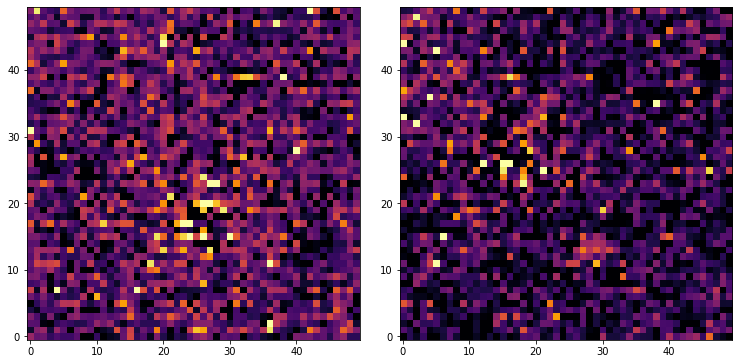

Loading of 1 cubes.
Number of dimension : 2
Initial images size (px) : 288 / 224
New images size (px)     : 288 / 224
Loading of 1 cubes.
Number of dimension : 2
Initial images size (px) : 288 / 224
New images size (px)     : 288 / 224


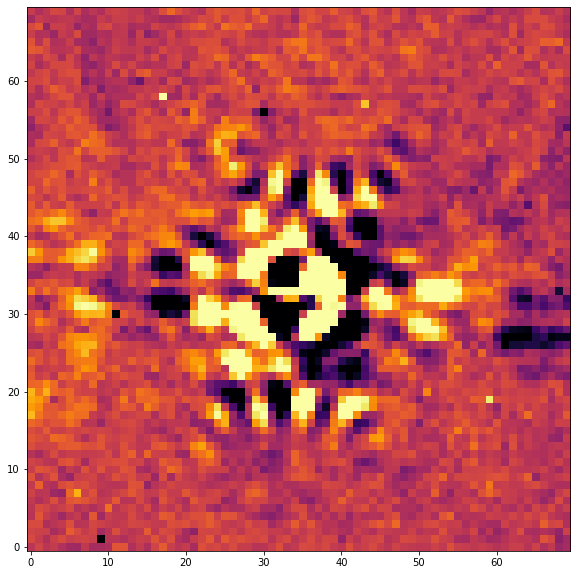

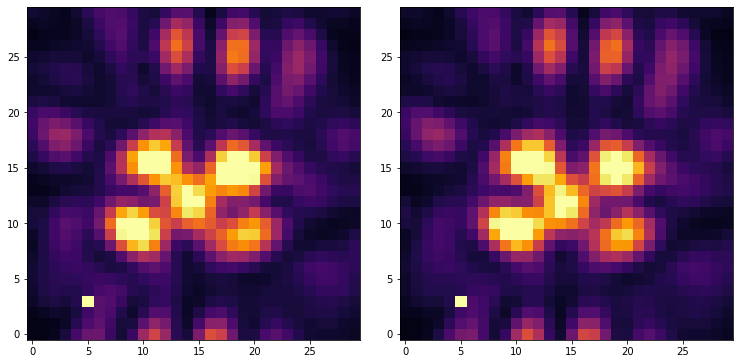

In [4]:
################
#### F1140C ####
################

# TA analysis

if True:
    path_TA_1  = '/home/cperrot/Work/raw/JWST/Target/MAST/P3662/output_with_photom/obs006/TA/'
    path_TA_2  = '/home/cperrot/Work/raw/JWST/Target/MAST/P3662/output_with_photom/obs007/TA/'

    TA_1 ,header_TA_1   = imp.load_cube(path_TA_1,'cal')
    TA_2 ,header_TA_2   = imp.load_cube(path_TA_2,'cal')

    diff_TA_pos1 = ndimage.shift(imp.clean_image_nan(TA_1[0]),[-0.12,0.05])-imp.clean_image_nan(TA_2[0])
    diff_TA_pos2 = ndimage.shift(imp.clean_image_nan(TA_1[1]),[-0.01,-0.02])-imp.clean_image_nan(TA_2[1])

    vmax=100
    vmin=-5
    fig1,[sub4,sub5] = plt.subplots(nrows=1,ncols=2,figsize=(10,8.5))
    plt.subplots_adjust(wspace=0.12, hspace=0.05, left=0.01, right=0.99)
    tmp4 = sub4.imshow(diff_TA_pos1[150:200,150:200],origin='lower',cmap='inferno',interpolation='none',vmin=vmin,vmax=vmax)
    tmp5 = sub5.imshow(diff_TA_pos2[100:150,120:170],origin='lower',cmap='inferno',interpolation='none',vmin=vmin,vmax=vmax)
    plt.show()



path_SCI_1  = '/home/cperrot/Work/raw/JWST/Target/MAST/P3662/output_with_photom/obs006/'
path_SCI_2  = '/home/cperrot/Work/raw/JWST/Target/MAST/P3662/output_with_photom/obs007/'
path_bkg    = '/home/cperrot/Work/raw/JWST/Target/MAST/P3662/output_with_photom/obs008/'

SCI_1 ,header_SCI_1   = imp.load_cube(path_SCI_1,'cal')
SCI_2 ,header_SCI_2   = imp.load_cube(path_SCI_2,'cal')
#BKG   ,header_BKG_2   = imp.load_cube(path_bkg,'P3662_008_HD181327_master_bkg_cal')
BKG = fits.open(path_bkg+'P3662_008_HD181327_master_bkg_cal.fits')[0].data
diff_SCI = ndimage.shift(imp.clean_image_nan(SCI_1),[-0.0,0.0])-imp.clean_image_nan(SCI_2)

vm=0.7
plt.figure(figsize=(10,10))
plt.imshow(diff_SCI[80:150,85:155],origin='lower',cmap='inferno',interpolation='none',vmin=vm*-1,vmax=vm)
plt.show()


fig1,[sub4,sub5] = plt.subplots(nrows=1,ncols=2,figsize=(10,8.5))
plt.subplots_adjust(wspace=0.12, hspace=0.05, left=0.01, right=0.99)
tmp4 = sub4.imshow((imp.clean_image_nan(SCI_1-BKG))[100:130,105:135],origin='lower',cmap='inferno',interpolation='none',vmin=0,vmax=30)
tmp5 = sub5.imshow((imp.clean_image_nan(SCI_2-BKG))[100:130,105:135],origin='lower',cmap='inferno',interpolation='none',vmin=0,vmax=30)
plt.show()

In [11]:
################
#### F1140C ####
################


#check les TA entre roll 1 et 2 pour le centrage


path_save = '/home/cperrot/Work/projet/JWST/Target/GO/P3662/output_with_photom/HD181327/'

if not os.path.exists(path_save):
    os.makedirs(path_save)

pixscale = 0.110 # arcsec
lam = 11.40e-6    # lambda en m


aff  = 'cal'

path_tar_1  = '/home/cperrot/Work/raw/JWST/Target/MAST/CAL/P03662/obs006/'
path_tar_2  = '/home/cperrot/Work/raw/JWST/Target/MAST/CAL/P03662/obs007/'
path_ref    = '/home/cperrot/Work/raw/JWST/Target/MAST/CAL/P03662/obs009/'

path_bkg_1  = '/home/cperrot/Work/raw/JWST/Target/MAST/MASTER_BKG/P03662/obs008/'
path_bkg_2  = '/home/cperrot/Work/raw/JWST/Target/MAST/MASTER_BKG/P03662/obs010/'


cube_tar_1 ,header_tar_1   = imp.load_cube(path_tar_1,aff)
cube_tar_2 ,header_tar_2   = imp.load_cube(path_tar_2,aff)
cube_ref  ,header_ref      = imp.load_cube(path_ref,aff)
 
min_bkg_1 = fits.open(glob.glob(path_bkg_1+'P*_master_bkg_cal.fits',recursive=False)[0])[0].data
min_bkg_2 = fits.open(glob.glob(path_bkg_2+'P*_master_bkg_cal.fits',recursive=False)[0])[0].data
    
#bkg subtraction
cube_tar_1 = cube_tar_1-min_bkg_1
cube_tar_2 = cube_tar_2-min_bkg_1
cube_ref   = cube_ref-min_bkg_2

if False:
    ### write SCI and REF fits after minimum bkg subtraction  
    hdu_list = fits.HDUList([fits.PrimaryHDU(header=header_tar_1[0]),fits.ImageHDU(data=cube_tar_1,header=header_tar_1[0])])
    hdu_list.writeto(path_save+'HD181327_roll-1_dither1_minimum_bkg_cal.fits',overwrite=True)
    hdu_list = fits.HDUList([fits.PrimaryHDU(header=header_tar_2[0]),fits.ImageHDU(data=cube_tar_2,header=header_tar_2[0])])
    hdu_list.writeto(path_save+'HD181327_roll-2_dither1_minimum_bkg_cal.fits',overwrite=True)
    hdu_list = fits.HDUList([fits.PrimaryHDU(header=header_ref[0][0]),fits.ImageHDU(data=cube_ref,header=header_ref[0][1])])
    hdu_list.writeto(path_save+'REF_HD203010_dither1-9_minimum_bkg_cal.fits',overwrite=True)  

clipval = 3.
cube_tar_1  = imp.sigma_clip_jwst(cube_tar_1,clipval)
cube_tar_2  = imp.sigma_clip_jwst(cube_tar_2,clipval)
cube_ref    = imp.sigma_clip_jwst(cube_ref,clipval)

#resize
newd = 200
x0 = 119
y0 = 112
scale=[(newd/2.)*pixscale,-1*(newd/2.)*pixscale,-1*(newd/2.)*pixscale,(newd/2.)*pixscale]

cube_tar_1 = cube_tar_1[y0-newd//2:y0+newd//2,x0-newd//2:x0+newd//2]
cube_tar_2 = cube_tar_2[y0-newd//2:y0+newd//2,x0-newd//2:x0+newd//2]
cube_ref   = cube_ref[:,y0-newd//2:y0+newd//2,x0-newd//2:x0+newd//2]

#PCA # commented because PCA is bad for this target
#PCA_1140_1 = imp.sub_PCA(cube_tar_1, cube_ref, [newd//2,newd//2], 2, dim=newd//2, plot=False)
#PCA_1140_2 = imp.sub_PCA(cube_tar_2, cube_ref, [newd//2,newd//2], 2, dim=newd//2, plot=False)

# flux scaling for RDI
f_scale_1 = imp.flux_scaling_ta(path_tar_1+'TA', path_ref+'TA', aff, lam)
f_scale_2 = imp.flux_scaling_ta(path_tar_2+'TA', path_ref+'TA', aff, lam)
print("f_scale_1 with TA : ",f_scale_1)
print("f_scale_2 with TA : ",f_scale_2)

#perform RDI with 1 roll and 1 reference
RDI_1140_1 = imp.RDI_classic(cube_tar_1, cube_ref, f_scale=f_scale_1)
RDI_1140_2 = imp.RDI_classic(cube_tar_2, cube_ref, f_scale=f_scale_2)

#subshift for roll 1
#RDI_1140_1 = RDI_classic(ndimage.shift(clean_image_nan(cube_tar_1),[0.0,0.1]), clean_image_nan(cube_ref), f_scale=f_scale_1)

#rotation
PA_V3_1 = header_tar_1[1]['PA_V3']     # 59.58852013851359
V3i_1   = header_tar_1[1]['V3I_YANG']  # 4.83544897
PA_V3_2 = header_tar_2[1]['PA_V3']     # 66.59658743620635
V3i_2   = header_tar_2[1]['V3I_YANG']  # 4.83544897

#PCA_1140_1 = ndimage.rotate(PCA_1140_1, -(PA_V3_1+V3i_1), reshape=False)
#PCA_1140_2 = ndimage.rotate(PCA_1140_2, -(PA_V3_2+V3i_2), reshape=False)
RDI_1140_1_c = np.copy(RDI_1140_1)
RDI_1140_2_c = np.copy(RDI_1140_2)
RDI_1140_1_c = imp.clean_image_nan(RDI_1140_1_c)
RDI_1140_2_c = imp.clean_image_nan(RDI_1140_2_c)
RDI_1140_1_r = ndimage.rotate(RDI_1140_1_c, -(PA_V3_1+V3i_1), reshape=False)
RDI_1140_2_r = ndimage.rotate(RDI_1140_2_c, -(PA_V3_2+V3i_2), reshape=False)

##PCA_1140_t = (PCA_1140_1+PCA_1140_2)/2.
RDI_1140_t = (RDI_1140_1+RDI_1140_2)/2.
RDI_1140_t_r = (RDI_1140_1_r+RDI_1140_2_r)/2.


imp.save_fits(RDI_1140_1,path_save+'RDI_1140_roll_1.fits')
imp.save_fits(RDI_1140_2,path_save+'RDI_1140_roll_2.fits')
imp.save_fits(RDI_1140_t,path_save+'RDI_1140_somme_roll.fits')
imp.save_fits(RDI_1140_1_r,path_save+'RDI_1140_roll_1_rot.fits')
imp.save_fits(RDI_1140_2_r,path_save+'RDI_1140_roll_2_rot.fits')
imp.save_fits(RDI_1140_t_r,path_save+'RDI_1140_somme_roll_rot.fits')

imp.save_fits(cube_tar_1,path_save+'cube_1140_pixelcorr_1.fits')
imp.save_fits(cube_tar_2,path_save+'cube_1140_pixelcorr_2.fits')

imp.save_fits(RDI_1140_1_c,path_save+'RDI_1140_roll_1_clean.fits')
imp.save_fits(RDI_1140_2_c,path_save+'RDI_1140_roll_2_clean.fits')
imp.save_fits(imp.clean_image_nan(cube_tar_1),path_save+'cube_1140_pixelcorr_1_clean.fits')
imp.save_fits(imp.clean_image_nan(cube_tar_2),path_save+'cube_1140_pixelcorr_2_clean.fits')




Loading of 1 cubes.
Number of dimension : 2
Initial images size (px) : 288 / 224
New images size (px)     : 288 / 224
Loading of 1 cubes.
Number of dimension : 2
Initial images size (px) : 288 / 224
New images size (px)     : 288 / 224
Loading of 9 cubes.
Number of dimension : 2
Initial images size (px) : 288 / 224
New images size (px)     : 288 / 224


/home/cperrot/anaconda3/envs/mirisim/lib/python3.9/site-packages/numpy/lib/nanfunctions.py:1218: RuntimeWarning: All-NaN slice encountered
  r, k = function_base._ureduce(a, func=_nanmedian, axis=axis, out=out,
/home/cperrot/anaconda3/envs/mirisim/lib/python3.9/site-packages/numpy/lib/nanfunctions.py:1879: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


Loading of 2 cubes.
Number of dimension : 2
Initial images size (px) : 288 / 224
New images size (px)     : 200 / 200
sigma model PSF:  1.3965812874037857
156 156
Roll - TA 1
Result : A = 16722.2 / x0 = 155.96 / y0 = 155.71 / width_x = 1.38 / width_y = 1.45
Stddev : A = 62.1 / x0 = 0.01 / y0 = 0.01 / width_x = 0.01 / width_y = 0.01
115 117
Roll - TA 2
Result : A = 16907.7 / x0 = 116.65 / y0 = 114.64 / width_x = 1.36 / width_y = 1.44
Stddev : A = 55.6 / x0 = 0.0 / y0 = 0.0 / width_x = 0.0 / width_y = 0.0
Loading of 2 cubes.
Number of dimension : 2
Initial images size (px) : 288 / 224
New images size (px)     : 200 / 200
157 156
Ref - TA 1
Result : A = 162998.0 / x0 = 155.66 / y0 = 157.05 / width_x = 1.39 / width_y = 1.45
Stddev : A = 227.6 / x0 = 0.0 / y0 = 0.0 / width_x = 0.0 / width_y = 0.0
115 117
Ref - TA 2
Result : A = 164010.8 / x0 = 116.61 / y0 = 114.57 / width_x = 1.38 / width_y = 1.45
Stddev : A = 225.3 / x0 = 0.0 / y0 = 0.0 / width_x = 0.0 / width_y = 0.0
Loading of 2 cubes.
N

In [12]:
# general plotting

if True:
    vmin=-1
    vmax=4

    #RDI
    scale=[(newd/2.)*pixscale,-1*(newd/2.)*pixscale,-1*(newd/2.)*pixscale,(newd/2.)*pixscale]
    fig1,[sub4,sub5] = plt.subplots(nrows=1,ncols=2,figsize=(10,8.5))
    plt.subplots_adjust(wspace=0.12, hspace=0.05, left=0.01, right=0.99)
    tmp4 = sub4.imshow(RDI_1140_1_r,origin='lower',cmap='inferno',interpolation='none',vmin=vmin,vmax=vmax,extent=scale)
    tmp5 = sub5.imshow(RDI_1140_2_r,origin='lower',cmap='inferno',interpolation='none',vmin=vmin,vmax=vmax,extent=scale)
    sub5.get_yaxis().set_visible(False)
    sub4.set_title('RDI - roll 1')
    sub5.set_title('RDI - roll 2')
    sub4.set_ylabel(r'$\Delta$ DEC [arcsec]')
    sub4.set_xlabel(r'$\Delta$ RA [arcsec]')
    sub5.set_xlabel(r'$\Delta$ RA [arcsec]')
    cax  = fig1.add_axes([1., 0.23, 0.02, 0.545])
    cbar = fig1.colorbar(tmp5, cax=cax, orientation='vertical')
    cbar.set_label('MJy/Sr',fontsize=10)
    cbar.ax.tick_params(length=2,pad=1,labelsize=10)
    fig1.savefig(path_save+'HD181327_RDI_1140_roll1-2.pdf',format='pdf',bbox_inches='tight')
    plt.close(fig1)




    #zoom
    z=50
    scale=[(newd/2.-z)*pixscale,-1*(newd/2.-z)*pixscale,-1*(newd/2.-z)*pixscale,(newd/2.-z)*pixscale]
    fig1,[sub4,sub5] = plt.subplots(nrows=1,ncols=2,figsize=(10,8.5))
    plt.subplots_adjust(wspace=0.12, hspace=0.05, left=0.01, right=0.99)
    tmp4 = sub4.imshow(RDI_1140_1_r[newd//2-z:newd//2+z,newd//2-z:newd//2+z],origin='lower',cmap='inferno',interpolation='none',vmin=vmin,vmax=vmax,extent=scale)
    tmp5 = sub5.imshow(RDI_1140_2_r[newd//2-z:newd//2+z,newd//2-z:newd//2+z],origin='lower',cmap='inferno',interpolation='none',vmin=vmin,vmax=vmax,extent=scale)
    sub5.get_yaxis().set_visible(False)
    sub4.set_title('RDI - roll 1')
    sub5.set_title('RDI - roll 2')
    sub4.set_ylabel(r'$\Delta$ DEC [arcsec]')
    sub4.set_xlabel(r'$\Delta$ RA [arcsec]')
    sub5.set_xlabel(r'$\Delta$ RA [arcsec]')
    cax  = fig1.add_axes([1., 0.23, 0.02, 0.545])
    cbar = fig1.colorbar(tmp5, cax=cax, orientation='vertical')
    cbar.set_label('MJy/Sr',fontsize=10)
    cbar.ax.tick_params(length=2,pad=1,labelsize=10)
    fig1.savefig(path_save+'HD181327_RDI_1140_roll1-2_zoom.pdf',format='pdf',bbox_inches='tight')
    plt.close(fig1)



    #RDI roll 2
    scale=[(newd/2.)*pixscale,-1*(newd/2.)*pixscale,-1*(newd/2.)*pixscale,(newd/2.)*pixscale]
    fig1 = plt.figure(figsize=(10,10))
    tmp = plt.imshow(RDI_1140_2_r,origin='lower',cmap='inferno',interpolation='none',vmin=-1,vmax=4,extent=scale)
    plt.title('RDI - roll 2')
    plt.ylabel(r'$\Delta$ DEC [arcsec]')
    plt.xlabel(r'$\Delta$ RA [arcsec]')
    cax  = fig1.add_axes([0.9, 0.125, 0.02, 0.76])
    cbar = fig1.colorbar(tmp, cax=cax, orientation='vertical')
    cbar.set_label('MJy/Sr',fontsize=10)
    cbar.ax.tick_params(length=2,pad=1,labelsize=10)
    fig1.savefig(path_save+'HD181327_RDI_1140_roll2.pdf',format='pdf',bbox_inches='tight')
    plt.close(fig1)

    #RDI roll 2 zoom
    z=50
    scale=[(newd/2.-z)*pixscale,-1*(newd/2.-z)*pixscale,-1*(newd/2.-z)*pixscale,(newd/2.-z)*pixscale]
    fig1 = plt.figure(figsize=(10,10))
    tmp = plt.imshow(RDI_1140_2_r[newd//2-z:newd//2+z,newd//2-z:newd//2+z],origin='lower',cmap='inferno',interpolation='none',vmin=vmin,vmax=vmax,extent=scale)
    plt.title('RDI - roll 2')
    plt.ylabel(r'$\Delta$ DEC [arcsec]')
    plt.xlabel(r'$\Delta$ RA [arcsec]')
    cax  = fig1.add_axes([0.9, 0.125, 0.02, 0.76])
    cbar = fig1.colorbar(tmp, cax=cax, orientation='vertical')
    cbar.set_label('MJy/Sr',fontsize=10)
    cbar.ax.tick_params(length=2,pad=1,labelsize=10)
    fig1.savefig(path_save+'HD181327_RDI_1140_roll2_zoom.pdf',format='pdf',bbox_inches='tight')
    plt.close(fig1)


    ### no rotation
    #RDI roll 2
    scale=[(newd/2.)*pixscale,-1*(newd/2.)*pixscale,-1*(newd/2.)*pixscale,(newd/2.)*pixscale]
    fig1 = plt.figure(figsize=(10,10))
    tmp = plt.imshow(RDI_1140_2,origin='lower',cmap='inferno',interpolation='none',vmin=-1,vmax=4,extent=scale)
    plt.title('RDI - roll 2')
    plt.ylabel(r'$\Delta$ DEC [arcsec]')
    plt.xlabel(r'$\Delta$ RA [arcsec]')
    cax  = fig1.add_axes([0.9, 0.125, 0.02, 0.76])
    cbar = fig1.colorbar(tmp, cax=cax, orientation='vertical')
    cbar.set_label('MJy/Sr',fontsize=10)
    cbar.ax.tick_params(length=2,pad=1,labelsize=10)
    fig1.savefig(path_save+'HD181327_RDI_1140_roll2_norotation.pdf',format='pdf',bbox_inches='tight')
    plt.close(fig1)

    #RDI roll 2 zoom
    z=50
    scale=[(newd/2.-z)*pixscale,-1*(newd/2.-z)*pixscale,-1*(newd/2.-z)*pixscale,(newd/2.-z)*pixscale]
    fig1 = plt.figure(figsize=(10,10))
    tmp = plt.imshow(RDI_1140_2[newd//2-z:newd//2+z,newd//2-z:newd//2+z],origin='lower',cmap='inferno',interpolation='none',vmin=vmin,vmax=vmax,extent=scale)
    plt.title('RDI - roll 2')
    plt.ylabel(r'$\Delta$ DEC [arcsec]')
    plt.xlabel(r'$\Delta$ RA [arcsec]')
    cax  = fig1.add_axes([0.9, 0.125, 0.02, 0.76])
    cbar = fig1.colorbar(tmp, cax=cax, orientation='vertical')
    cbar.set_label('MJy/Sr',fontsize=10)
    cbar.ax.tick_params(length=2,pad=1,labelsize=10)
    fig1.savefig(path_save+'HD181327_RDI_1140_roll2_norotation_zoom.pdf',format='pdf',bbox_inches='tight')
    plt.close(fig1)

    ### no rotation
    #RDI roll 2
    scale=[(newd/2.)*pixscale,-1*(newd/2.)*pixscale,-1*(newd/2.)*pixscale,(newd/2.)*pixscale]
    fig1 = plt.figure(figsize=(10,10))
    tmp = plt.imshow(RDI_1140_2_c,origin='lower',cmap='inferno',interpolation='none',vmin=-1,vmax=4,extent=scale)
    plt.title('RDI - roll 2')
    plt.ylabel(r'$\Delta$ DEC [arcsec]')
    plt.xlabel(r'$\Delta$ RA [arcsec]')
    cax  = fig1.add_axes([0.9, 0.125, 0.02, 0.76])
    cbar = fig1.colorbar(tmp, cax=cax, orientation='vertical')
    cbar.set_label('MJy/Sr',fontsize=10)
    cbar.ax.tick_params(length=2,pad=1,labelsize=10)
    fig1.savefig(path_save+'HD181327_RDI_1140_roll2_norotation_clean.pdf',format='pdf',bbox_inches='tight')
    plt.close(fig1)

    #RDI roll 2 zoom
    z=50
    scale=[(newd/2.-z)*pixscale,-1*(newd/2.-z)*pixscale,-1*(newd/2.-z)*pixscale,(newd/2.-z)*pixscale]
    fig1 = plt.figure(figsize=(10,10))
    tmp = plt.imshow(RDI_1140_2_c[newd//2-z:newd//2+z,newd//2-z:newd//2+z],origin='lower',cmap='inferno',interpolation='none',vmin=vmin,vmax=vmax,extent=scale)
    plt.title('RDI - roll 2')
    plt.ylabel(r'$\Delta$ DEC [arcsec]')
    plt.xlabel(r'$\Delta$ RA [arcsec]')
    cax  = fig1.add_axes([0.9, 0.125, 0.02, 0.76])
    cbar = fig1.colorbar(tmp, cax=cax, orientation='vertical')
    cbar.set_label('MJy/Sr',fontsize=10)
    cbar.ax.tick_params(length=2,pad=1,labelsize=10)
    fig1.savefig(path_save+'HD181327_RDI_1140_roll2_norotation_clean_zoom.pdf',format='pdf',bbox_inches='tight')
    plt.close(fig1)




    #ADI
    scale=[(newd/2.)*pixscale,-1*(newd/2.)*pixscale,-1*(newd/2.)*pixscale,(newd/2.)*pixscale]
    fig1,[sub1,sub2] = plt.subplots(nrows=1,ncols=2,figsize=(10,8.5))
    plt.subplots_adjust(wspace=0.12, hspace=0.05, left=0.01, right=0.99)
    tmp1 = sub1.imshow(cube_tar_1-cube_tar_2,origin='lower',cmap='inferno',interpolation='none',vmin=vmin,vmax=vmax,extent=scale)
    tmp2 = sub2.imshow(cube_tar_2-cube_tar_1,origin='lower',cmap='inferno',interpolation='none',vmin=vmin,vmax=vmax,extent=scale)
    sub1.set_title('ADI R1 - R2')
    sub2.set_title('ADI R2 - R1')
    sub1.set_ylabel(r'$\Delta$ DEC [arcsec]')
    sub1.set_xlabel(r'$\Delta$ RA [arcsec]')
    sub2.set_xlabel(r'$\Delta$ RA [arcsec]')
    cax  = fig1.add_axes([1., 0.23, 0.02, 0.545])
    cbar = fig1.colorbar(tmp1, cax=cax, orientation='vertical')
    cbar.set_label('MJy/Sr',fontsize=10)
    cbar.ax.tick_params(length=2,pad=1,labelsize=10)
    fig1.savefig(path_save+'HD181327_ADI_1140.pdf',format='pdf',bbox_inches='tight')
    plt.close(fig1)




    #corono image
    scale=[(newd/2.)*pixscale,-1*(newd/2.)*pixscale,-1*(newd/2.)*pixscale,(newd/2.)*pixscale]
    fig1,[sub1,sub2,sub3] = plt.subplots(nrows=1,ncols=3,figsize=(20,17))
    plt.subplots_adjust(wspace=0.12, hspace=0.05, left=0.01, right=0.99)
    tmp1 = sub1.imshow(cube_tar_1,origin='lower',cmap='inferno',interpolation='none',vmin=-2,vmax=20,extent=scale)
    tmp2 = sub2.imshow(cube_tar_2,origin='lower',cmap='inferno',interpolation='none',vmin=-2,vmax=20,extent=scale)
    tmp3 = sub3.imshow(cube_ref[0],origin='lower',cmap='inferno',interpolation='none',vmin=-18,vmax=180,extent=scale)
    sub1.set_title('roll 1')
    sub2.set_title('roll 2')
    sub3.set_title('reference')
    sub1.set_ylabel(r'$\Delta$ DEC [arcsec]')
    sub1.set_xlabel(r'$\Delta$ RA [arcsec]')
    sub2.set_xlabel(r'$\Delta$ RA [arcsec]')
    sub3.set_xlabel(r'$\Delta$ RA [arcsec]')
    cax  = fig1.add_axes([0.685, 0.27, 0.31, 0.02])
    cbar = fig1.colorbar(tmp3, cax=cax, orientation='horizontal')
    cbar.set_label('MJy/Sr',fontsize=10)
    cbar.ax.tick_params(length=2,pad=1,labelsize=10)
    cax2  = fig1.add_axes([0.01, 0.27, 0.64, 0.02])
    cbar2 = fig1.colorbar(tmp1, cax=cax2, orientation='horizontal')
    cbar2.set_label('MJy/Sr',fontsize=10)
    cbar2.ax.tick_params(length=2,pad=1,labelsize=10)
    fig1.savefig(path_save+'HD181327_corono_img_1140.pdf',format='pdf',bbox_inches='tight')
    plt.close(fig1)




    #BKG
    '''
    # plus trop utile
    vmin=4
    vmax=7
    scale=[(newd/2.)*pixscale,-1*(newd/2.)*pixscale,-1*(newd/2.)*pixscale,(newd/2.)*pixscale]
    fig1,[sub1,sub2] = plt.subplots(nrows=1,ncols=2,figsize=(10,8.5))
    plt.subplots_adjust(wspace=0.12, hspace=0.05, left=0.01, right=0.99)
    tmp1 = sub1.imshow(cube_bkg[0,:,:],origin='lower',cmap='inferno',interpolation='none',vmin=vmin,vmax=vmax,extent=scale)
    tmp2 = sub2.imshow(cube_bkg[1,:,:],origin='lower',cmap='inferno',interpolation='none',vmin=vmin,vmax=vmax,extent=scale)
    sub1.set_title('Background dither 1')
    sub2.set_title('Background dither 2')
    sub1.set_ylabel(r'$\Delta$ DEC [arcsec]')
    sub1.set_xlabel(r'$\Delta$ RA [arcsec]')
    sub2.set_xlabel(r'$\Delta$ RA [arcsec]')
    cax  = fig1.add_axes([1., 0.23, 0.02, 0.545])
    cbar = fig1.colorbar(tmp1, cax=cax, orientation='vertical')
    cbar.set_label('ADU',fontsize=10)
    cbar.ax.tick_params(length=2,pad=1,labelsize=10)
    fig1.savefig(path_save+'HD181327_BKG_1140.pdf',format='pdf',bbox_inches='tight')
    plt.close(fig1)
    '''


    #roll 2 rate
    '''
    # plus trop utilevmin=4
    vmax=14
    scale=[(newd/2.)*pixscale,-1*(newd/2.)*pixscale,-1*(newd/2.)*pixscale,(newd/2.)*pixscale]
    fig1,[sub1,sub2] = plt.subplots(nrows=1,ncols=2,figsize=(10,8.5))
    plt.subplots_adjust(wspace=0.12, hspace=0.05, left=0.01, right=0.99)
    tmp1 = sub1.imshow(cube_tar1_rate,origin='lower',cmap='inferno',interpolation='none',vmin=vmin,vmax=vmax,extent=scale)
    tmp2 = sub2.imshow(cube_tar_rate,origin='lower',cmap='inferno',interpolation='none',vmin=vmin,vmax=vmax,extent=scale)
    sub1.set_title('Roll 1 RAW')
    sub2.set_title('Roll 2 RAW')
    sub1.set_ylabel(r'$\Delta$ DEC [arcsec]')
    sub1.set_xlabel(r'$\Delta$ RA [arcsec]')
    sub2.set_xlabel(r'$\Delta$ RA [arcsec]')
    cax  = fig1.add_axes([1., 0.23, 0.02, 0.545])
    cbar = fig1.colorbar(tmp1, cax=cax, orientation='vertical')
    cbar.set_label('ADU',fontsize=10)
    cbar.ax.tick_params(length=2,pad=1,labelsize=10)
    fig1.savefig(path_save+'HD181327_RAW_1140.pdf',format='pdf',bbox_inches='tight')
    plt.close(fig1)
    '''


In [9]:
## plot for talk


if False:
    #cube_tar_1
    #cube_tar_2 imagemagick
    z=25
    newd=200
    vmin=-1
    vmax=20
    scale=[(newd/2.-z)*pixscale,-1*(newd/2.-z)*pixscale,-1*(newd/2.-z)*pixscale,(newd/2.-z)*pixscale]
    fig = plt.figure()
    ims = []
    im = plt.imshow(cube_tar_1[newd//2-z:newd//2+z,newd//2-z:newd//2+z],origin='lower',cmap='inferno',interpolation='none',vmin=vmin,vmax=vmax,extent=scale)
    ims.append([im])
    im = plt.imshow(cube_tar_2[newd//2-z:newd//2+z,newd//2-z:newd//2+z],origin='lower',cmap='inferno',interpolation='none',vmin=vmin,vmax=vmax,extent=scale)
    ims.append([im])
    ani = animation.ArtistAnimation(fig, ims, interval=50, blit=True, repeat_delay=500)
    writer = PillowWriter(fps=2)
    ani.save(path_save+"Roll1_roll2.gif", writer=writer)

    fig = plt.figure()
    ims = []
    im = plt.imshow(cube_tar_1[newd//2-z:newd//2+z,newd//2-z:newd//2+z],origin='lower',cmap='inferno',interpolation='none',vmin=vmin,vmax=vmax,extent=scale)
    ims.append([im])
    im = plt.imshow(cube_ref[0,newd//2-z:newd//2+z,newd//2-z:newd//2+z],origin='lower',cmap='inferno',interpolation='none',vmin=vmin,vmax=180,extent=scale)
    ims.append([im])
    ani = animation.ArtistAnimation(fig, ims, interval=50, blit=True, repeat_delay=500)
    writer = PillowWriter(fps=2)
    ani.save(path_save+"Roll1_ref.gif", writer=writer)

    fig = plt.figure()
    ims = []
    im = plt.imshow(cube_tar_2[newd//2-z:newd//2+z,newd//2-z:newd//2+z],origin='lower',cmap='inferno',interpolation='none',vmin=vmin,vmax=vmax,extent=scale)
    ims.append([im])
    im = plt.imshow(cube_ref[0,newd//2-z:newd//2+z,newd//2-z:newd//2+z],origin='lower',cmap='inferno',interpolation='none',vmin=vmin,vmax=180,extent=scale)
    ims.append([im])
    ani = animation.ArtistAnimation(fig, ims, interval=50, blit=True, repeat_delay=500)
    writer = PillowWriter(fps=2)
    ani.save(path_save+"Roll2_ref.gif", writer=writer)


    z=50
    vmin=-18
    vmax=180
    fig = plt.figure()
    ims = []
    for i in range(9):
        im = plt.imshow(cube_ref[i,newd//2-z:newd//2+z,newd//2-z:newd//2+z],origin='lower',cmap='inferno',interpolation='none',vmin=vmin,vmax=vmax,extent=scale)
        ims.append([im])
    ani = animation.ArtistAnimation(fig, ims, interval=50, blit=True, repeat_delay=500)
    writer = PillowWriter(fps=2)
    ani.save(path_save+"reference.gif", writer=writer)




No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


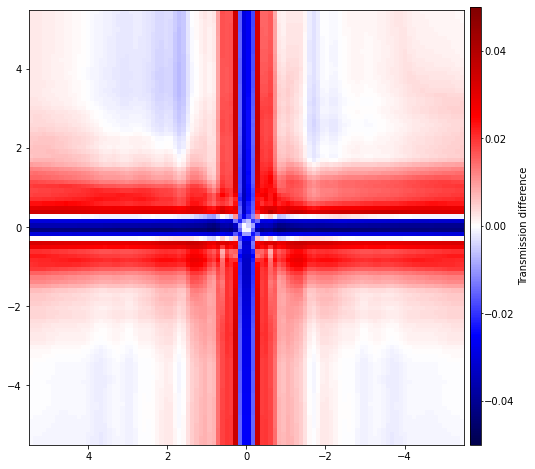

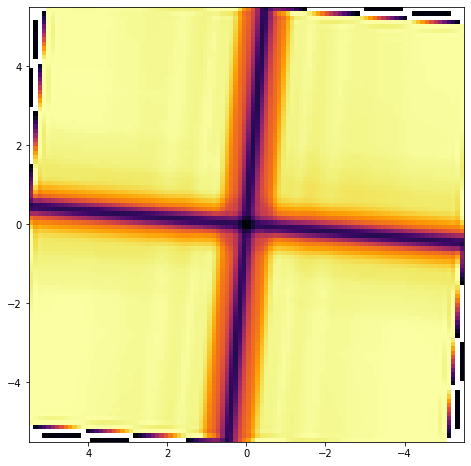

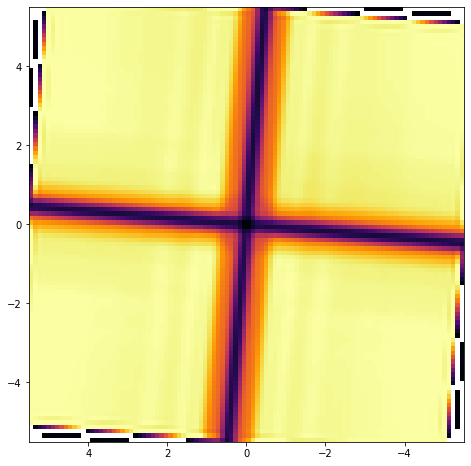

In [13]:
### calcul de l'attenuation du corono avec le code d'Anthony

path_sim = '/home/cperrot/Work/projet/JWST/Target/GO/P3662/output_with_photom/planet_attenuation/'

#NW
filename_1  = 'MIRI_2024_attenuation_NW_HD181327_F1140C.fits'
file_sepx_1 = 'MIRI_2024_attenuation_NW_HD181327_F1140C_SEP-X.fits'
file_sepy_1 = 'MIRI_2024_attenuation_NW_HD181327_F1140C_SEP-Y.fits'

#SW
filename_2  = 'MIRI_2024_attenuation_SW_HD181327_F1140C.fits'
file_sepx_2 = 'MIRI_2024_attenuation_SW_HD181327_F1140C_SEP-X.fits'
file_sepy_2 = 'MIRI_2024_attenuation_SW_HD181327_F1140C_SEP-Y.fits'

#NE
filename_3  = 'MIRI_2024_attenuation_NE_HD181327_F1140C.fits'
file_sepx_3 = 'MIRI_2024_attenuation_NE_HD181327_F1140C_SEP-X.fits'
file_sepy_3 = 'MIRI_2024_attenuation_NE_HD181327_F1140C_SEP-Y.fits'

#SE
filename_4  = 'MIRI_2024_attenuation_SE_HD181327_F1140C.fits'
file_sepx_4 = 'MIRI_2024_attenuation_SE_HD181327_F1140C_SEP-X.fits'
file_sepy_4 = 'MIRI_2024_attenuation_SE_HD181327_F1140C_SEP-Y.fits'


image = RDI_1140_2_c.copy() #copie de l'image RDI roll 2
V3i_1   = header_tar_1[1]['V3I_YANG']  # 4.83544897 #4QPM rotation
ydim = np.shape(image)[-2]
xdim = np.shape(image)[-1]


#lam*3600*180/6.5/np.pi*1.5/pixscale # taille en pixel de 1.5 lambda/D
mask2 = np.ndarray([200,200],dtype=bool)*False
mask_psf = np.ndarray([6,6],dtype=bool)
mask_psf = [[False, True, True, True, True, False],
           [True, True, True, True, True, True],
           [True, True, True, True, True, True],
           [True, True, True, True, True, True],
           [True, True, True, True, True, True],
           [False, True, True, True, True, False]]



#NW + initialisation
file  = fits.open(path_sim+filename_1)
fileX = fits.open(path_sim+file_sepx_1)
fileY = fits.open(path_sim+file_sepy_1)
psf_coro = file[0].data
npsf= np.shape(psf_coro)[0]
plan_sepX = np.zeros(npsf*4, dtype='float32')
plan_sepY = np.zeros(npsf*4, dtype='float32')
max_psf   = np.zeros(npsf*4, dtype='float32')
sum_psf   = np.zeros(npsf*4, dtype='float32')
plan_sepX[:npsf] = fileX[0].data
plan_sepY[:npsf] = fileY[0].data
file.close()
fileX.close()
fileY.close()
for i in range(npsf):
    max_psf[i] = np.max(psf_coro[i,:,:])
    cpsfx = round(plan_sepX[i]/pixscale + 0.5) #centre de la PSF
    cpsfy = round(plan_sepY[i]/pixscale + 0.5) #centre de la PSF
    mask_cpsf = mask2.copy()
    mask_cpsf[ydim//2+cpsfy-3:ydim//2+cpsfy+3,xdim//2+cpsfx-3:xdim//2+cpsfx+3] = mask_psf
    mask_sel = (mask_cpsf == True)
    sum_psf[i] = np.sum(psf_coro[i,mask_sel])

#SW
file  = fits.open(path_sim+filename_2)
fileX = fits.open(path_sim+file_sepx_2)
fileY = fits.open(path_sim+file_sepy_2)   
psf_coro = file[0].data
plan_sepX[1*npsf:2*npsf] = fileX[0].data
plan_sepY[1*npsf:2*npsf] = fileY[0].data    
file.close()
fileX.close()
fileY.close()      
for i in range(npsf):
    max_psf[i+1*npsf] = np.max(psf_coro[i,:,:])
    cpsfx = round(plan_sepX[i+1*npsf]/pixscale + 0.5) #centre de la PSF
    cpsfy = round(plan_sepY[i+1*npsf]/pixscale + 0.5) #centre de la PSF
    mask_cpsf = mask2.copy()
    mask_cpsf[ydim//2+cpsfy-3:ydim//2+cpsfy+3,xdim//2+cpsfx-3:xdim//2+cpsfx+3] = mask_psf
    mask_sel = (mask_cpsf == True)
    sum_psf[i+1*npsf] = np.sum(psf_coro[i,mask_sel])
    
#NE

file  = fits.open(path_sim+filename_3)
fileX = fits.open(path_sim+file_sepx_3)
fileY = fits.open(path_sim+file_sepy_3)   
psf_coro = file[0].data
plan_sepX[2*npsf:3*npsf] = fileX[0].data
plan_sepY[2*npsf:3*npsf] = fileY[0].data    
file.close()
fileX.close()
fileY.close()       
for i in range(npsf):
    max_psf[i+2*npsf] = np.max(psf_coro[i,:,:])
    cpsfx = round(plan_sepX[i+2*npsf]/pixscale + 0.5) #centre de la PSF
    cpsfy = round(plan_sepY[i+2*npsf]/pixscale + 0.5) #centre de la PSF
    mask_cpsf = mask2.copy()
    mask_cpsf[ydim//2+cpsfy-3:ydim//2+cpsfy+3,xdim//2+cpsfx-3:xdim//2+cpsfx+3] = mask_psf
    mask_sel = (mask_cpsf == True)
    sum_psf[i+2*npsf] = np.sum(psf_coro[i,mask_sel])
    
#SE
file  = fits.open(path_sim+filename_4)
fileX = fits.open(path_sim+file_sepx_4)
fileY = fits.open(path_sim+file_sepy_4)   
psf_coro = file[0].data
plan_sepX[3*npsf:4*npsf] = fileX[0].data
plan_sepY[3*npsf:4*npsf] = fileY[0].data    
file.close()
fileX.close()
fileY.close()    
for i in range(npsf):
    max_psf[i+3*npsf] = np.max(psf_coro[i,:,:])
    cpsfx = round(plan_sepX[i+3*npsf]/pixscale + 0.5) #centre de la PSF
    cpsfy = round(plan_sepY[i+3*npsf]/pixscale + 0.5) #centre de la PSF
    mask_cpsf = mask2.copy()
    mask_cpsf[ydim//2+cpsfy-3:ydim//2+cpsfy+3,xdim//2+cpsfx-3:xdim//2+cpsfx+3] = mask_psf
    mask_sel = (mask_cpsf == True)
    sum_psf[i+3*npsf] = np.sum(psf_coro[i,mask_sel])
    
    

max_psf /= np.max(max_psf)
sum_psf /= np.max(sum_psf)


fig1,[sub1,sub2] = plt.subplots(nrows=1,ncols=2,figsize=(25,15))
plt.subplots_adjust(wspace=0.12, hspace=0.05, left=0.01, right=0.99)
for i in range(50):
    sub1.plot(plan_sepX[i*50:(i+1)*50],max_psf[i*50:(i+1)*50],'o')
    sub2.plot(plan_sepX[i*50:(i+1)*50],sum_psf[i*50:(i+1)*50],'o')
sub1.legend()
sub2.legend()
sub1.set_title('Max')
sub2.set_title('Total')
sub1.set_ylabel('Flux')
sub1.set_xlabel('Separation [arcsec]')
sub2.set_xlabel('Separation [arcsec]')
fig1.savefig(path_save+'HD181327_transmission_cut_max_and_sum.pdf',format='pdf',bbox_inches='tight')
plt.close(fig1)

#fig1 = plt.figure(figsize=(10,10))
#plt.plot(plan_sepX/pixscale,plan_sepY/pixscale,'o')
#plt.xlim([-55,55])
#plt.ylim([-55,55])
#plt.show()





transmi_max = np.zeros([ydim,xdim])


for i in range(round(np.sqrt(npsf))):
    for j in range(round(np.sqrt(npsf))):
        transmi_max[ydim//2+i,xdim//2+j] = max_psf[i*round(np.sqrt(npsf))+j]
        transmi_max[ydim//2+i,xdim//2-j-1] = max_psf[i*round(np.sqrt(npsf))+j+1*npsf]
        transmi_max[ydim//2-i-1,xdim//2+j] = max_psf[i*round(np.sqrt(npsf))+j+2*npsf]
        transmi_max[ydim//2-i-1,xdim//2-j-1] = max_psf[i*round(np.sqrt(npsf))+j+3*npsf]

transmi_sum = np.zeros([ydim,xdim])


for i in range(round(np.sqrt(npsf))):
    for j in range(round(np.sqrt(npsf))):
        transmi_sum[ydim//2+i,xdim//2+j] = sum_psf[i*round(np.sqrt(npsf))+j]
        transmi_sum[ydim//2+i,xdim//2-j-1] = sum_psf[i*round(np.sqrt(npsf))+j+1*npsf]
        transmi_sum[ydim//2-i-1,xdim//2+j] = sum_psf[i*round(np.sqrt(npsf))+j+2*npsf]
        transmi_sum[ydim//2-i-1,xdim//2-j-1] = sum_psf[i*round(np.sqrt(npsf))+j+3*npsf]

#### difference between both method       
imp.save_fits(transmi_sum-transmi_max,path_save+'diff_transmission_sum-max.fits')
ydim = 200
xdim = 200
scale=[(xdim/2.-50)*pixscale,-1*(xdim/2.-50)*pixscale,-1*(ydim/2.-50)*pixscale,(ydim/2.-50)*pixscale]
fig1 = plt.figure(figsize=(8,8))
tmp = plt.imshow((transmi_sum-transmi_max)[ydim//2-50:ydim//2+50,xdim//2-50:xdim//2+50],origin='lower',cmap='seismic',interpolation='none',vmin=-0.05,vmax=0.05,extent=scale)
cax  = fig1.add_axes([0.9, 0.125, 0.02, 0.76])
cbar = fig1.colorbar(tmp, cax=cax, orientation='vertical')
cbar.set_label('Transmission difference',fontsize=10)
cbar.ax.tick_params(length=2,pad=1,labelsize=10)
plt.show()
fig1.savefig(path_save+'diff_transmission_sum-max.pdf',format='pdf',bbox_inches='tight')
plt.close(fig1)


### rotation of the transmission map to fit with the real image
#scale=[(xdim/2.-40)*pixscale,-1*(xdim/2.-40)*pixscale,-1*(ydim/2.-40)*pixscale,(ydim/2.-40)*pixscale]        
transmi_max = ndimage.rotate(transmi_max, (V3i_1), reshape=False)        
transmi_max[transmi_max <= 0.01] = math.nan
plt.figure(figsize=(8,8))
plt.imshow(transmi_max[ydim//2-50:ydim//2+50,xdim//2-50:xdim//2+50],origin='lower',cmap='inferno',interpolation='none',vmin=0.0,vmax=1,extent=scale)
plt.show()
        
        
transmi_sum = ndimage.rotate(transmi_sum, (V3i_1), reshape=False)        
transmi_sum[transmi_sum <= 0.01] = math.nan
plt.figure(figsize=(8,8))
plt.imshow(transmi_sum[ydim//2-50:ydim//2+50,xdim//2-50:xdim//2+50],origin='lower',cmap='inferno',interpolation='none',vmin=0.0,vmax=1,extent=scale)
plt.show()


imp.save_fits(transmi_sum,path_save+'transmi_sum.fits')
imp.save_fits(transmi_max,path_save+'transmi_max.fits')








In [11]:
#test du centrage du masque sur la PSF

if False:
    mask_psf = np.ndarray([6,6],dtype=bool)
    mask_psf = [[False, True, True, True, True, False],
               [True, True, True, True, True, True],
               [True, True, True, True, True, True],
               [True, True, True, True, True, True],
               [True, True, True, True, True, True],
               [False, True, True, True, True, False]]

    i = 524
    cpsfx = round(plan_sepX[i+2*npsf]/pixscale + 0.5) #centre de la PSF
    cpsfy = round(plan_sepY[i+2*npsf]/pixscale + 0.5) #centre de la PSF
    mask_cpsf = mask2.copy()
    mask_cpsf[ydim//2+cpsfy-3:ydim//2+cpsfy+3,xdim//2+cpsfx-3:xdim//2+cpsfx+3] = mask_psf
    mask_sel = (mask_cpsf == True)
    plt.imshow((psf_coro[i,:,:]*mask_cpsf)[100:125,65:90],origin='lower',cmap='inferno',interpolation='none',vmin=0,vmax=0.03)
    plt.show()


    cpsfx = round(plan_sepX[i+3*npsf]/pixscale + 0.5) #centre de la PSF
    cpsfy = round(plan_sepY[i+3*npsf]/pixscale + 0.5) #centre de la PSF
    mask_cpsf = mask2.copy()
    mask_cpsf[ydim//2+cpsfy-3:ydim//2+cpsfy+3,xdim//2+cpsfx-3:xdim//2+cpsfx+3] = mask_psf
    mask_sel = (mask_cpsf == True)
    plt.imshow((psf_coro[i,:,:]*mask_cpsf)[100:125,65:90],origin='lower',cmap='inferno',interpolation='none',vmin=0,vmax=0.03)
    plt.show()

Simulated offaxis PSF and corono
Intensity PSF coro: 0.015625808033468684
Intensity PSF off-axe: 0.6814142590766856
Ratio PSF coro/off-axe: 0.022931436824702802
Ratio PSF off-axe/coro: 43.60825741729161


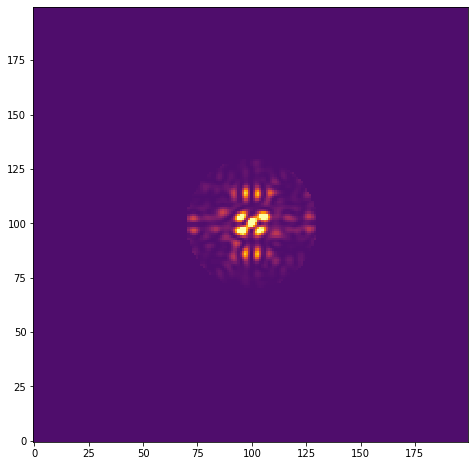

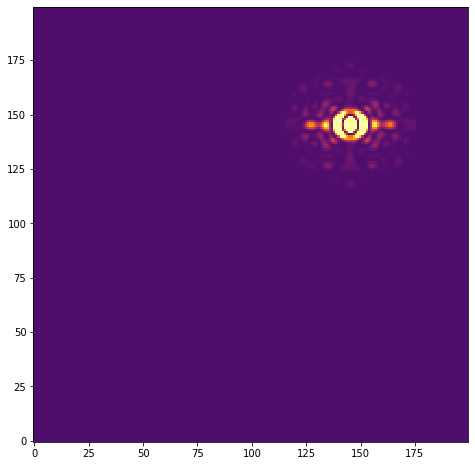

In [12]:
### Creation de la PSF hors-axe à partir des simulation

path_sim = '/home/cperrot/Work/projet/JWST/Target/GO/P3662/output_with_photom/planet_attenuation/'

filename  = 'MIRI_2024_corono_for_contrast_HD181327_F1140C.fits'
file_sepx = 'MIRI_2024_corono_for_contrast_HD181327_F1140C_SEP-X.fits'
file_sepy = 'MIRI_2024_corono_for_contrast_HD181327_F1140C_SEP-Y.fits'


image = RDI_1140_2_c.copy() #copie de l'image RDI roll 2
ydim = np.shape(image)[-2]
xdim = np.shape(image)[-1]


#lam*3600*180/6.5/np.pi*1.5/pixscale # taille en pixel de 1.5 lambda/D
mask2 = np.ndarray([ydim,xdim],dtype=bool)*False
mask_psf = np.ndarray([6,6],dtype=bool)
mask_psf = [[False, True, True, True, True, False],
           [True, True, True, True, True, True],
           [True, True, True, True, True, True],
           [True, True, True, True, True, True],
           [True, True, True, True, True, True],
           [False, True, True, True, True, False]]

mask = np.concatenate([np.arange(-100.,-0.,1)*(-1),np.arange(-0.,100.,1)])
mask = np.sqrt(mask**2+mask[:,np.newaxis]**2)
maskh = np.concatenate([np.arange(-99.5-46,0.5-46,1)*(-1),np.arange(0.5-46,100.5-46,1)])
maskh = np.sqrt(maskh**2+maskh[:,np.newaxis]**2)

##### PSF coro et hors axis simulée
file      = fits.open(path_sim+filename)
fileX     = fits.open(path_sim+file_sepx)
fileY     = fits.open(path_sim+file_sepy)

psf_simu  = file[0].data
psf_coro  = psf_simu[0,:,:]
psf_off   = psf_simu[1,:,:]
plan_sepX = fileX[0].data
plan_sepY = fileY[0].data
file.close()
fileX.close()
fileY.close()

r_mask = 30

int_psf_coro = np.sum(psf_coro*(mask<r_mask))
int_psf_off  = np.sum(psf_off*(maskh<r_mask))
print("Simulated offaxis PSF and corono")
print("Intensity PSF coro:",int_psf_coro)
print("Intensity PSF off-axe:",int_psf_off)
print("Ratio PSF coro/off-axe:",int_psf_coro/int_psf_off)
print("Ratio PSF off-axe/coro:",int_psf_off/int_psf_coro)

coef_con1 = int_psf_coro/int_psf_off


plt.figure(figsize=(8,8))
plt.imshow(psf_coro*(mask<r_mask),origin='lower',cmap='inferno',interpolation='none',vmin=-0.000015,vmax=0.00005)
plt.show()
plt.figure(figsize=(8,8))
plt.imshow(psf_off*(maskh<r_mask),origin='lower',cmap='inferno',interpolation='none',vmin=-0.0003,vmax=0.001)
plt.show()


####################################################################################################################################
######
######
###### VERIFIER RATIO PSF CORO / PSF HORS AXE EN FONCTION DU RAYON D'INTEGRATION DU FLUX
######
######
####################################################################################################################################


COMM 1037 offaxis PSF and corono
Intensity Comm PSF coro: 22599.05
Intensity Comm PSF off-axe: 1427732.5
Ratio Comm PSF coro/off-axe: 0.015828632
Ratio Comm PSF off-axe/coro: 63.17666


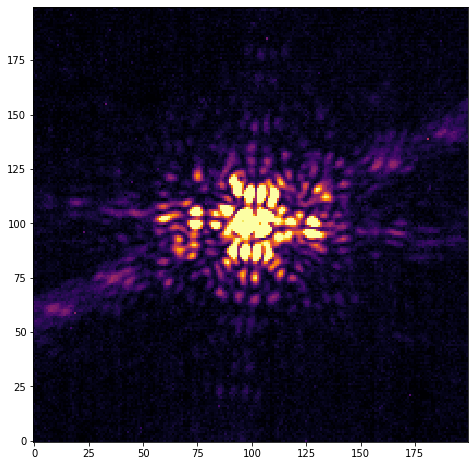

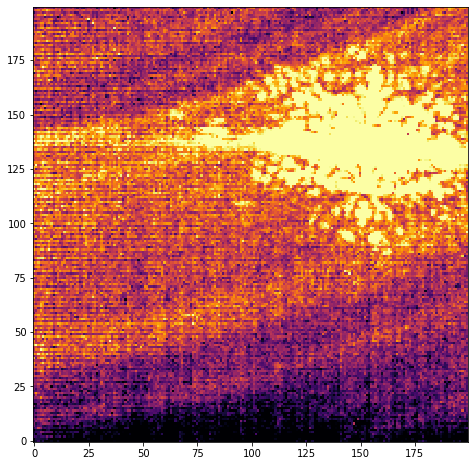

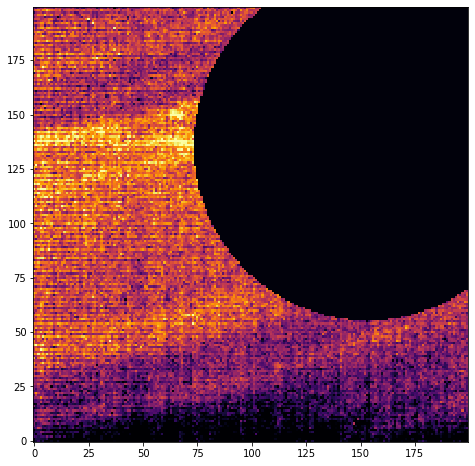

22.201603

In [13]:
### Creation de la PSF hors-axe à partir du comm 1037


filecomcoro = '/home/cperrot/Work/raw/JWST/Target/MAST/Comm/P1037/output_with_photom/obs005/Comm_corono_dither1_cal.fits'
filecomoff  = '/home/cperrot/Work/raw/JWST/Target/MAST/Comm/P1037/output_with_photom/obs006/Comm_off_axis_dither2_cal.fits'
filecombkg1 = '/home/cperrot/Work/raw/JWST/Target/MAST/Comm/P1045/output_with_photom/obs065/Comm_background_dither1_cal.fits'
filecombkg2 = '/home/cperrot/Work/raw/JWST/Target/MAST/Comm/P1045/output_with_photom/obs065/Comm_background_dither2_cal.fits'
filecombkg3 = '/home/cperrot/Work/raw/JWST/Target/MAST/Comm/P1045/output_with_photom/obs065/Comm_background_dither3_cal.fits'
filecombkg4 = '/home/cperrot/Work/raw/JWST/Target/MAST/Comm/P1045/output_with_photom/obs065/Comm_background_dither4_cal.fits'


image = RDI_1140_2_c.copy() #copie de l'image RDI roll 2
ydim = np.shape(image)[-2]
xdim = np.shape(image)[-1]


#lam*3600*180/6.5/np.pi*1.5/pixscale # taille en pixel de 1.5 lambda/D
mask2 = np.ndarray([ydim,xdim],dtype=bool)*False
mask_psf = np.ndarray([6,6],dtype=bool)
mask_psf = [[False, True, True, True, True, False],
           [True, True, True, True, True, True],
           [True, True, True, True, True, True],
           [True, True, True, True, True, True],
           [True, True, True, True, True, True],
           [False, True, True, True, True, False]]

mask = np.concatenate([np.arange(-99.5,0.5,1)*(-1),np.arange(0.5,100.5,1)])
mask = np.sqrt(mask**2+mask[:,np.newaxis]**2)
maskcom1 = np.concatenate([np.arange(-99.5-54,0.5-54,1)*(-1),np.arange(0.5-54,100.5-54,1)])
maskcom2 = np.concatenate([np.arange(-99.5-36,0.5-36,1)*(-1),np.arange(0.5-36,100.5-36,1)])
maskcom = np.sqrt(maskcom1**2+maskcom2[:,np.newaxis]**2)


##### PSF coro et hors axis COMM 1037
filecom_coro = fits.open(filecomcoro)
filecom_TA   = fits.open(filecomoff)
psfcom_coro  = filecom_coro[1].data
psfcom_off   = filecom_TA[1].data

filecom_bkg1 = fits.open(filecombkg1)
filecom_bkg2 = fits.open(filecombkg2)
filecom_bkg3 = fits.open(filecombkg3)
filecom_bkg4 = fits.open(filecombkg4)
com_bkg  = filecom_bkg1[1].data+filecom_bkg2[1].data+filecom_bkg3[1].data+filecom_bkg4[1].data
com_bkg /= 4.

newd = 200
xd = np.shape(psfcom_coro)[1]
yd = np.shape(psfcom_coro)[0]
x0 = 119
y0 = 112
scale=[(newd/2.)*pixscale,-1*(newd/2.)*pixscale,-1*(newd/2.)*pixscale,(newd/2.)*pixscale]
psfcom_coro = psfcom_coro[y0-newd//2:y0+newd//2,x0-newd//2:x0+newd//2]
psfcom_off  = psfcom_off[y0-newd//2:y0+newd//2,x0-newd//2:x0+newd//2]
com_bkg     = com_bkg[y0-newd//2:y0+newd//2,x0-newd//2:x0+newd//2]

filecom_coro.close()
filecom_TA.close()
filecom_bkg1.close()
filecom_bkg2.close()
filecom_bkg3.close()
filecom_bkg4.close()

clipval = 3.
psfcom_coro = imp.sigma_clip_jwst(psfcom_coro,clipval)
psfcom_off  = imp.sigma_clip_jwst(psfcom_off,clipval)
com_bkg     = imp.clean_image_nan(com_bkg)
imp.save_fits(com_bkg,'/home/cperrot/Work/raw/JWST/Target/MAST/Comm/P1045/output_with_photom/obs065/background_mean.fits')
## soustraction du bkg
psfcom_coro -= com_bkg
psfcom_off  -= com_bkg
psfcom_coro = imp.clean_image_nan(psfcom_coro)
psfcom_off  = imp.clean_image_nan(psfcom_off)

r_mask = 30

int_psfcom_coro = np.sum(psfcom_coro*(mask<r_mask))
int_psfcom_off  = np.sum(psfcom_off*(maskcom<r_mask))
print("COMM 1037 offaxis PSF and corono")
print("Intensity Comm PSF coro:",int_psfcom_coro)
print("Intensity Comm PSF off-axe:",int_psfcom_off)
print("Ratio Comm PSF coro/off-axe:",int_psfcom_coro/int_psfcom_off)
print("Ratio Comm PSF off-axe/coro:",int_psfcom_off/int_psfcom_coro)
#print(int_psfcom_coro,int_psfcom_off,int_psfcom_coro/int_psfcom_off,int_psfcom_off/int_psfcom_coro)
contrast_comm = int_psfcom_coro/int_psfcom_off


plt.figure(figsize=(8,8))
plt.imshow(psfcom_coro,origin='lower',cmap='inferno',interpolation='none',vmin=-1,vmax=10) #*(mask<30)
plt.show()
plt.figure(figsize=(8,8))
plt.imshow(psfcom_off,origin='lower',cmap='inferno',interpolation='none',vmin=-1,vmax=50) #*(maskcom<30)
plt.show()

plt.figure(figsize=(8,8))
plt.imshow(psfcom_off*(maskcom>80),origin='lower',cmap='inferno',interpolation='none',vmin=-1,vmax=50) #*(maskcom<30)
plt.show()
np.median(psfcom_off[maskcom>80])


/home/cperrot/anaconda3/envs/mirisim/lib/python3.9/site-packages/numpy/lib/nanfunctions.py:1218: RuntimeWarning: All-NaN slice encountered
  r, k = function_base._ureduce(a, func=_nanmedian, axis=axis, out=out,
/tmp/ipykernel_16677/634325135.py:18: RuntimeWarning: Mean of empty slice
  cst_moy_c.append(np.nanmean((copy_psfcom_coro[(mask>i-2) & (mask<=i)]/int_psfcom_off)))
/home/cperrot/anaconda3/envs/mirisim/lib/python3.9/site-packages/numpy/lib/nanfunctions.py:1879: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


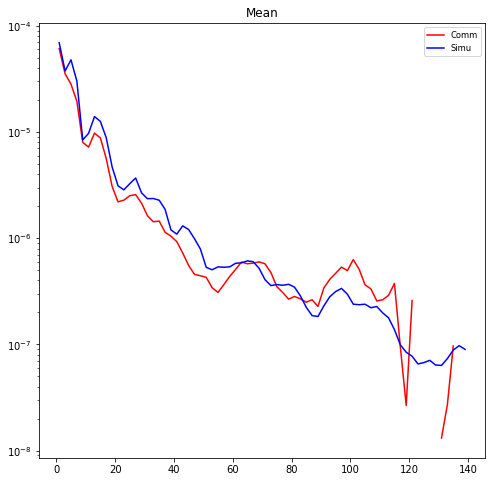

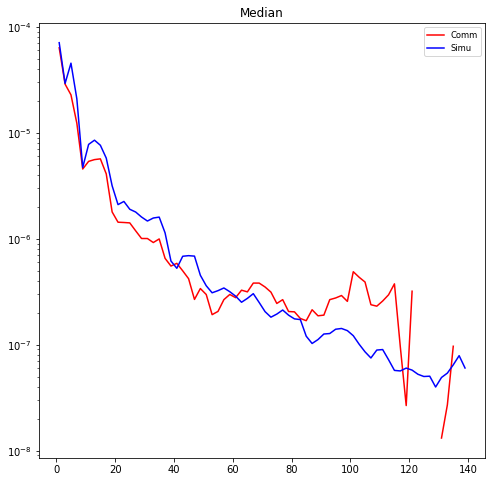

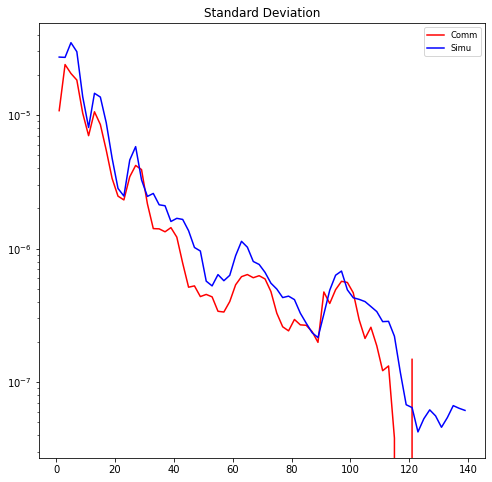

Simulated offaxis PSF and corono
0.022975349531862012
COMM 1037 offaxis PSF and corono
0.01587533


In [14]:
# comparaison SIMU vs COMM 1037
# profil des images corono simulées et de comm, divisée par l'int de la PSF hors axe associée

cst_std_c = []
cst_med_c = []
cst_moy_c = []
cst_std_s = []
cst_med_s = []
cst_moy_s = []

copy_psf_coro = psf_coro.copy() #copie de la PSF coro simulée
copy_psfcom_coro = psfcom_coro.copy() #copie de la PSF coro du comm

copy_psf_coro[np.where(copy_psf_coro <=0 )] = math.nan            #valeur neg en NaN pour pas affecterla moyenne/med/std
copy_psfcom_coro[np.where(copy_psfcom_coro <=0 )] = math.nan      #valeur neg en NaN pour pas affecterla moyenne/med/std
for i in np.arange(2,141,2):
    cst_med_c.append(np.nanmedian((copy_psfcom_coro[(mask>i-2) & (mask<=i)]/int_psfcom_off)))
    cst_moy_c.append(np.nanmean((copy_psfcom_coro[(mask>i-2) & (mask<=i)]/int_psfcom_off)))
    cst_std_c.append(np.nanstd((copy_psfcom_coro[(mask>i-2) & (mask<=i)]/int_psfcom_off)))
    cst_med_s.append(np.nanmedian((copy_psf_coro[(mask>i-2) & (mask<=i)]/int_psf_off)))
    cst_moy_s.append(np.nanmean((copy_psf_coro[(mask>i-2) & (mask<=i)]/int_psf_off)))
    cst_std_s.append(np.nanstd((copy_psf_coro[(mask>i-2) & (mask<=i)]/int_psf_off)))
    
plt.figure(figsize=(8,8))
plt.plot(np.arange(1,140,2),cst_moy_c,color='red',label='Comm')
plt.plot(np.arange(1,140,2),cst_moy_s,color='blue',label='Simu')
plt.title('Mean')
plt.yscale('log')
plt.legend(loc='upper right',fontsize='small')
#plt.ylim(1e-1,1e2)
plt.show()

plt.figure(figsize=(8,8))
plt.plot(np.arange(1,140,2),cst_med_c,color='red',label='Comm')
plt.plot(np.arange(1,140,2),cst_med_s,color='blue',label='Simu')
plt.title('Median')
plt.yscale('log')
plt.legend(loc='upper right',fontsize='small')
#plt.ylim(1e-1,1e2)
plt.show()

plt.figure(figsize=(8,8))
plt.plot(np.arange(1,140,2),cst_std_c,color='red',label='Comm')
plt.plot(np.arange(1,140,2),cst_std_s,color='blue',label='Simu')
plt.title('Standard Deviation')
plt.yscale('log')
plt.legend(loc='upper right',fontsize='small')
#plt.ylim(1e-1,1e2)
plt.show()


print("Simulated offaxis PSF and corono")
print(np.nansum(copy_psf_coro*(mask<30)/int_psf_off))
print("COMM 1037 offaxis PSF and corono")
print(np.nansum(copy_psfcom_coro*(mask<30)/int_psfcom_off))




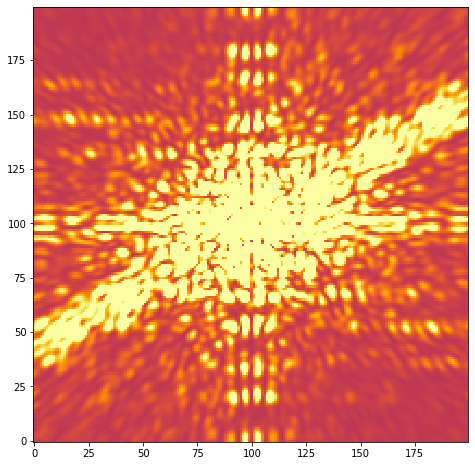

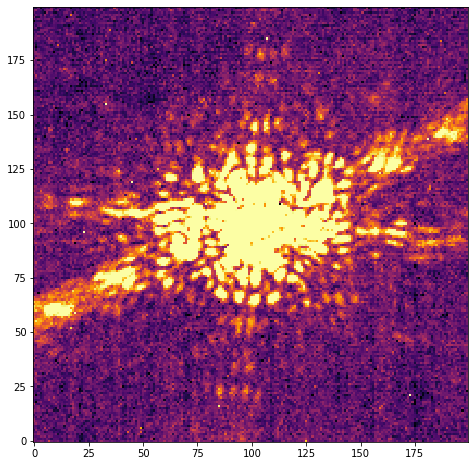

In [15]:
plt.figure(figsize=(8,8))
plt.imshow(psf_coro*(mask<300)/int_psf_off,origin='lower',cmap='inferno',interpolation='none',vmin=-1e-6,vmax=1e-6) #*(mask<30)
plt.show()
plt.figure(figsize=(8,8))
plt.imshow(psfcom_coro*(mask<300)/int_psfcom_off,origin='lower',cmap='inferno',interpolation='none',vmin=-1e-6,vmax=1e-6) #*(maskcom<30)
plt.show()

Optimization terminated successfully.
         Current function value: 1861.863758
         Iterations: 153
         Function evaluations: 292
rescale flux 425434.5196058151
Delta X 0.293629718652632
Delta Y 0.7565634852737901


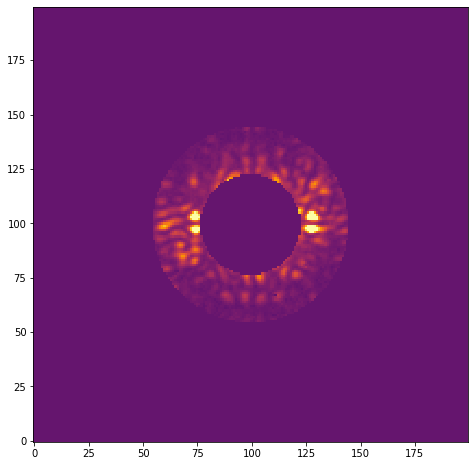

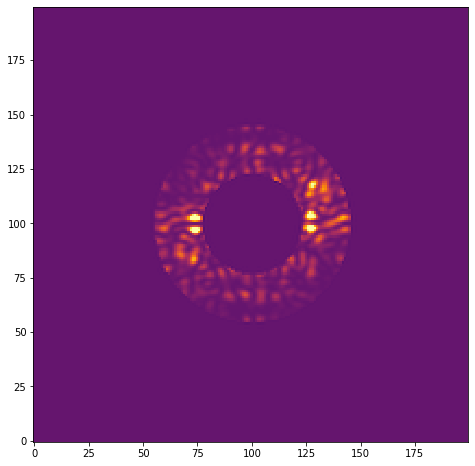

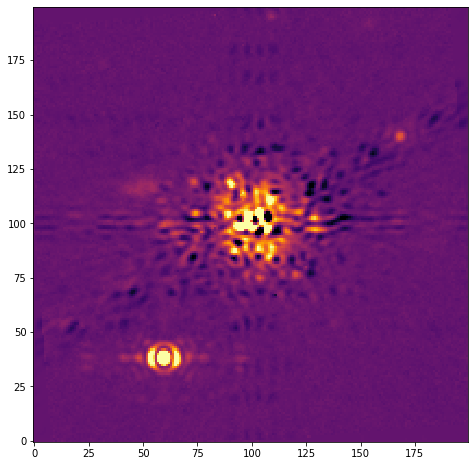

Optimization terminated successfully.
         Current function value: 2324.200828
         Iterations: 29
         Function evaluations: 62
rescale flux 404509.1652870178


"\nplt.figure(figsize=(8,8))\nplt.imshow(im_coro_mask,origin='lower',cmap='inferno',interpolation='none',vmin=-2,vmax=5)\nplt.show()\nplt.figure(figsize=(8,8))\nplt.imshow(P*psf_coro_mask,origin='lower',cmap='inferno',interpolation='none',vmin=-2,vmax=5)\nplt.show()\n\nplt.figure(figsize=(8,8))\nplt.imshow(im_coro-P*psf_coro,origin='lower',cmap='seismic',interpolation='none',vmin=-5,vmax=5)\nplt.show()\nplt.figure(figsize=(8,8))\nplt.imshow(im_coro-P*psf_coro,origin='lower',cmap='inferno',interpolation='none',vmin=-2,vmax=5)\nplt.show()\n"

In [16]:
### calcul du ratio entre l'image corono simulée et scientifique pour construire la PSF scientifique

filecoro = '/home/cperrot/Work/projet/JWST/Target/GO/P3662/output_with_photom/HD181327_roll-2_dither1_minimum_bkg_cal.fits'
fileTA   = '/home/cperrot/Work/raw/JWST/Target/MAST/P3662/output_with_photom/obs007/TA/P3662_007_HD181327_TA_dither2_cal.fits'


file_coro = fits.open(filecoro)
file_TA   = fits.open(fileTA)
im_coro   = file_coro[1].data
im_TA     = file_TA[1].data
file_coro.close()
file_TA.close()

#resize
newd = 200
xd = np.shape(im_coro)[1]
yd = np.shape(im_coro)[0]
x0 = 119
y0 = 112
im_coro = im_coro[y0-newd//2:y0+newd//2,x0-newd//2:x0+newd//2]

im_coro = imp.sigma_clip_jwst(im_coro,3)
im_coro = imp.clean_image_nan(im_coro)
im_coro = ndimage.rotate(im_coro, -(V3i_1), reshape=False)        


im_coro_mask  = (im_coro*(mask>23)*(mask<45))
psf_coro_mask = (psf_coro*(mask>23)*(mask<45))





## opti by mathilde
def function_min_shift(P):
    data = im_coro_mask 
    model = psf_coro_mask
    return np.sum((data - P[0]*ndimage.shift(model, [P[1], P[2]]))**2.)

def function_min(P):
    data = im_coro_mask 
    model = psf_coro_mask
    return np.sum((data - P[0]*model)**2.)
    

P = optimize.fmin(function_min_shift, x0=(4e5, 0.0, 0.0))
print("rescale flux", P[0])
print("Delta X", P[1])
print("Delta Y", P[2])

plt.figure(figsize=(8,8))
plt.imshow(im_coro_mask,origin='lower',cmap='inferno',interpolation='none',vmin=-2,vmax=5)
plt.show()
plt.figure(figsize=(8,8))
plt.imshow(P[0]*ndimage.shift(psf_coro_mask, [P[1], P[2]]),origin='lower',cmap='inferno',interpolation='none',vmin=-2,vmax=5)
plt.show()

#plt.figure(figsize=(8,8))
#plt.imshow(im_coro-P[0]*ndimage.shift(psf_coro, [P[1], P[2]]),origin='lower',cmap='seismic',interpolation='none',vmin=-5,vmax=5)
#plt.show()
plt.figure(figsize=(8,8))
plt.imshow(im_coro-P[0]*ndimage.shift(psf_coro, [P[1], P[2]]),origin='lower',cmap='inferno',interpolation='none',vmin=-2,vmax=5)
plt.show()


#im_coro_flat  = (im_coro*(mask>10)*(mask<45)).flatten()
#psf_coro_flat = (psf_coro*(mask>10)*(mask<45)).flatten()

#def fct_subtraction(img, coef, xx, yy):
#    return ndimage.shift(img, [xx, yy]) * coef


#popt, pcov = curve_fit(fct_subtraction, psf_coro_flat, im_coro_flat, p0=[4e5,0.0,0.0])
#stdd = np.sqrt(np.diag(pcov))
#print(stdd)
#print(popt)
P = optimize.fmin(function_min, x0=(4e5))
print("rescale flux", P[0])

'''
plt.figure(figsize=(8,8))
plt.imshow(im_coro_mask,origin='lower',cmap='inferno',interpolation='none',vmin=-2,vmax=5)
plt.show()
plt.figure(figsize=(8,8))
plt.imshow(P*psf_coro_mask,origin='lower',cmap='inferno',interpolation='none',vmin=-2,vmax=5)
plt.show()

plt.figure(figsize=(8,8))
plt.imshow(im_coro-P*psf_coro,origin='lower',cmap='seismic',interpolation='none',vmin=-5,vmax=5)
plt.show()
plt.figure(figsize=(8,8))
plt.imshow(im_coro-P*psf_coro,origin='lower',cmap='inferno',interpolation='none',vmin=-2,vmax=5)
plt.show()
'''

### faire un subpixel shift pour bien center l'image
### ajuste le mask pour exclure le disque

#RDI_1140_1 = ndimage.shift(clean_image_nan(cube_tar_1),[0.0,0.1])




Optimization terminated successfully.
         Current function value: 713.981995
         Iterations: 43
         Function evaluations: 84
rescale flux 0.33598079861435837
Delta X 0.0006617318677825034
Delta Y 0.0008204257064020411


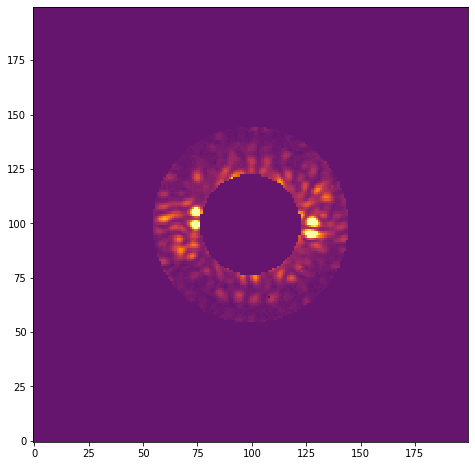

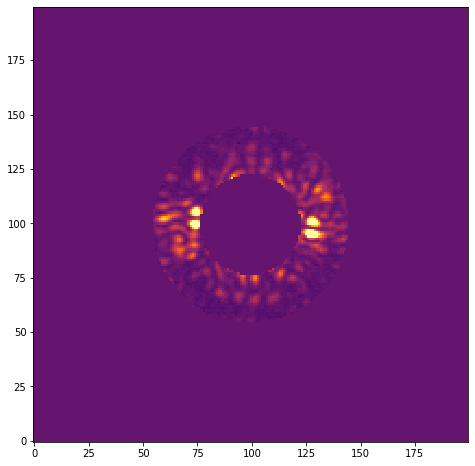

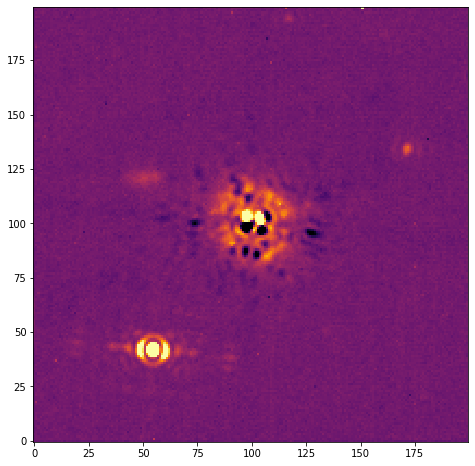

Optimization terminated successfully.
         Current function value: 713.777588
         Iterations: 17
         Function evaluations: 34
rescale flux 0.33603515624999947
contrast PSF coro / psf hors axe :  0.015828632
ratio comm/science coro :  0.33598079861435837


In [17]:
### calcul du ratio entre l'image corono COMM 1037 et scientifique pour construire la PSF scientifique

filecoro = '/home/cperrot/Work/projet/JWST/Target/GO/P3662/output_with_photom/HD181327_roll-2_dither1_minimum_bkg_cal.fits'


file_coro = fits.open(filecoro)
im_coro   = file_coro[1].data
file_coro.close()

#resize
newd = 200
xd = np.shape(im_coro)[1]
yd = np.shape(im_coro)[0]
x0 = 119
y0 = 112
im_coro = im_coro[y0-newd//2:y0+newd//2,x0-newd//2:x0+newd//2]

im_coro = imp.sigma_clip_jwst(im_coro,3)
im_coro = imp.clean_image_nan(im_coro)

im_coro_mask  = (im_coro*(mask>23)*(mask<45))
psfcom_coro_mask = (psfcom_coro*(mask>23)*(mask<45))

## opti by mathilde
def function_min_shift(P):
    data = im_coro_mask 
    model = psfcom_coro_mask
    return np.sum((data - P[0]*ndimage.shift(model, [P[1], P[2]]))**2.)

def function_min(P):
    data = im_coro_mask 
    model = psfcom_coro_mask
    return np.sum((data - P[0]*model)**2.)
    
#avec shift 
P = optimize.fmin(function_min_shift, x0=(1e0, 0.0, 0.0))
print("rescale flux", P[0])
print("Delta X", P[1])
print("Delta Y", P[2])

plt.figure(figsize=(8,8))
plt.imshow(im_coro_mask,origin='lower',cmap='inferno',interpolation='none',vmin=-2,vmax=5)
plt.show()
plt.figure(figsize=(8,8))
plt.imshow(P[0]*ndimage.shift(psfcom_coro_mask, [P[1], P[2]]),origin='lower',cmap='inferno',interpolation='none',vmin=-2,vmax=5)
plt.show()

plt.figure(figsize=(8,8))
plt.imshow(im_coro-P[0]*ndimage.shift(psfcom_coro, [P[1], P[2]]),origin='lower',cmap='inferno',interpolation='none',vmin=-2,vmax=5)
plt.show()


#pas de shift
Pb = optimize.fmin(function_min, x0=(1e0))
print("rescale flux", Pb[0])


new_PSF = psfcom_off*P[0]
print("contrast PSF coro / psf hors axe : ",contrast_comm)
print("ratio comm/science coro : ", P[0])

## courbe de contraste a 45° avec atténuation
## PSF synthétique du comm pour faire fake planètes pour valider la courbe de contraste
## travailler DANS le disque

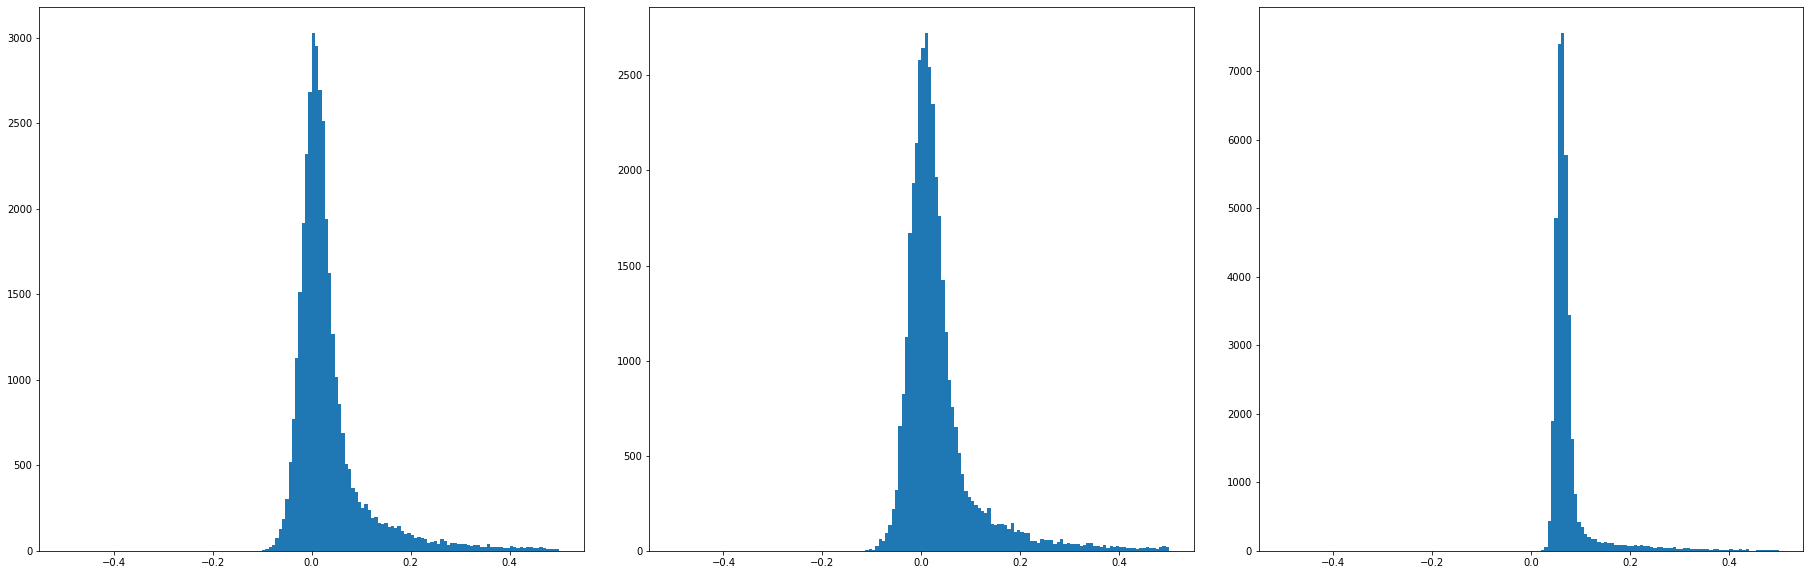

In [6]:
### methode 1 : balayage des pixels avec un zone de la taille de la PSF


image = RDI_1140_2_c.copy() #copie de l'image RDI roll 2

### supprimer manuellement les pixels mort restant 
pixel_mort=[[66,108],[57,107],[79,123],[81,143],[93,136],[117,137],[129,137],[98,77],[83,105],[91,90],[90,91],[91,92]]
for i in pixel_mort:
    image[i[0],i[1]] = math.nan
imp.clean_image_nan(image)



### création du mask mobile de r=3 pixel
mask2 = np.ndarray([200,200],dtype=bool)*False

mask_psf = np.ndarray([5,5],dtype=bool)

mask_psf = [[False, True, True, True, False],
           [True, True, True, True, True],
           [True, True, True, True, True],
           [True, True, True, True, True],
           [False, True, True, True, False]]



ydim = np.shape(image)[-2]
xdim = np.shape(image)[-1]
scale=[(xdim/2.)*pixscale,-1*(xdim/2.)*pixscale,-1*(ydim/2.)*pixscale,(ydim/2.)*pixscale]

mean_m1 = np.ndarray([ydim,xdim])
std_m1 = np.ndarray([ydim,xdim])
med_m1 = np.ndarray([ydim,xdim])

### calcul de la moyenne, median et std dev local pour chaque pixel hors bords sur 2 pixels
for i in range(ydim):
    for j in range(xdim):
        if (i < 2) or (j < 2) or (i > ydim-3) or (j > xdim-3):
            med_m1[i,j] = 0.
            mean_m1[i,j] = 0.
            std_m1[i,j] = 0.
        else:
            mask_op = mask2.copy()
            mask_op[i-2:i+3,j-2:j+3] = mask_psf
            mask2_sel = (mask_op == True)
            med_m1[i,j] = np.median(image[mask2_sel])
            std_m1[i,j] = np.std(image[mask2_sel])
            mean_m1[i,j] = np.mean(image[mask2_sel])

            
### création des map d'exclusion en fonction de la moyenne, median ou std dev
map_exclu_m1 = std_m1 < 0.1
map_exclu2_m1 = (mean_m1 > -0.1) * (mean_m1 < 0.1)
map_exclu3_m1 = (med_m1 > -0.1) * (med_m1 < 0.1)
#mean[mean > 0.1] = 0

fig1,[sub1,sub2,sub3] = plt.subplots(nrows=1,ncols=3,figsize=(25,10))
plt.subplots_adjust(wspace=0.12, hspace=0.05, left=0.01, right=0.99)
sub1.imshow(image,origin='lower',cmap='inferno',interpolation='none',vmin=-0.5,vmax=2.5,extent=scale)
sub2.imshow(std_m1,origin='lower',cmap='inferno',interpolation='none',vmin=-0.3,vmax=0.3,extent=scale)
sub3.imshow(std_m1*map_exclu_m1,origin='lower',cmap='inferno',interpolation='none',vmin=-0.3,vmax=0.3,extent=scale)
fig1.savefig(path_save+'HD181327_m1_stddev_mask.pdf',format='pdf',bbox_inches='tight')
plt.close(fig1)

fig1,[sub1,sub2,sub3] = plt.subplots(nrows=1,ncols=3,figsize=(25,10))
plt.subplots_adjust(wspace=0.12, hspace=0.05, left=0.01, right=0.99)
sub1.imshow(image,origin='lower',cmap='inferno',interpolation='none',vmin=-0.5,vmax=2.5,extent=scale)
sub2.imshow(mean_m1,origin='lower',cmap='inferno',interpolation='none',vmin=-0.3,vmax=0.3,extent=scale)
sub3.imshow(mean_m1*map_exclu2_m1,origin='lower',cmap='inferno',interpolation='none',vmin=-0.3,vmax=0.3,extent=scale)
fig1.savefig(path_save+'HD181327_m1_mean_mask.pdf',format='pdf',bbox_inches='tight')
plt.close(fig1)

fig1,[sub1,sub2,sub3] = plt.subplots(nrows=1,ncols=3,figsize=(25,10))
plt.subplots_adjust(wspace=0.12, hspace=0.05, left=0.01, right=0.99)
sub1.imshow(image,origin='lower',cmap='inferno',interpolation='none',vmin=-0.5,vmax=2.5,extent=scale)
sub2.imshow(med_m1,origin='lower',cmap='inferno',interpolation='none',vmin=-0.3,vmax=0.3,extent=scale)
sub3.imshow(med_m1*map_exclu3_m1,origin='lower',cmap='inferno',interpolation='none',vmin=-0.3,vmax=0.3,extent=scale)
fig1.savefig(path_save+'HD181327_m1_med_mask.pdf',format='pdf',bbox_inches='tight')
plt.close(fig1)

fig1,[sub1,sub2,sub3] = plt.subplots(nrows=1,ncols=3,figsize=(25,10))
plt.subplots_adjust(wspace=0.12, hspace=0.05, left=0.01, right=0.99)
sub1.imshow(image*map_exclu_m1,origin='lower',cmap='inferno',interpolation='none',vmin=-0.3,vmax=0.3,extent=scale)
sub2.imshow(image*map_exclu2_m1,origin='lower',cmap='inferno',interpolation='none',vmin=-0.3,vmax=0.3,extent=scale)
sub3.imshow(image*map_exclu3_m1,origin='lower',cmap='inferno',interpolation='none',vmin=-0.3,vmax=0.3,extent=scale)
fig1.savefig(path_save+'HD181327_m1_image_diff_mask.pdf',format='pdf',bbox_inches='tight')
plt.close(fig1)

fig1,[sub1,sub2,sub3] = plt.subplots(nrows=1,ncols=3,figsize=(25,10))
plt.subplots_adjust(wspace=0.12, hspace=0.05, left=0.01, right=0.99)
sub1.imshow(map_exclu_m1,origin='lower',cmap='inferno',interpolation='none',vmin=-0.3,vmax=0.3,extent=scale)
sub2.imshow(map_exclu2_m1,origin='lower',cmap='inferno',interpolation='none',vmin=-0.3,vmax=0.3,extent=scale)
sub3.imshow(map_exclu3_m1,origin='lower',cmap='inferno',interpolation='none',vmin=-0.3,vmax=0.3,extent=scale)
fig1.savefig(path_save+'HD181327_m1_diff_mask.pdf',format='pdf',bbox_inches='tight')
plt.close(fig1)

fig1,[sub1,sub2,sub3] = plt.subplots(nrows=1,ncols=3,figsize=(25,10))
plt.subplots_adjust(wspace=0.12, hspace=0.05, left=0.01, right=0.99)
sub1.hist(mean_m1[2:ydim-2,2:xdim-2].flatten(), bins=150, range=(-0.5,0.5),log=False)
sub2.hist(med_m1[2:ydim-2,2:xdim-2].flatten(), bins=150, range=(-0.5,0.5),log=False)
sub3.hist(std_m1[2:ydim-2,2:xdim-2].flatten(), bins=150, range=(-0.5,0.5),log=False)
plt.show()



fig1 = plt.figure(figsize=(10,10))
plt.imshow(std_m1,origin='lower',cmap='inferno',interpolation='none',vmin=0.0,vmax=0.7,extent=scale)
fig1.savefig(path_save+'HD181327_m1_std_dev_map.pdf',format='pdf',bbox_inches='tight')
plt.close(fig1)

fig1 = plt.figure(figsize=(10,10))
plt.imshow(med_m1,origin='lower',cmap='inferno',interpolation='none',vmin=0.0,vmax=1,extent=scale)
fig1.savefig(path_save+'HD181327_m1_median_map.pdf',format='pdf',bbox_inches='tight')
plt.close(fig1)

fig1 = plt.figure(figsize=(10,10))
plt.imshow(mean_m1,origin='lower',cmap='inferno',interpolation='none',vmin=0.0,vmax=1,extent=scale)
fig1.savefig(path_save+'HD181327_m1_mean_map.pdf',format='pdf',bbox_inches='tight')
plt.close(fig1)


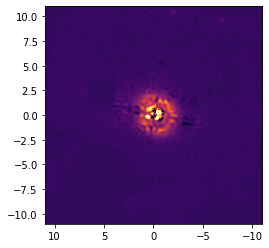

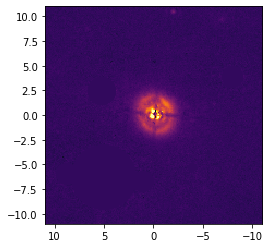

0.055 2.145e-18
0.165 3.037e-18
0.275 2.959e-18
0.385 2.098e-18
0.495 1.899e-18
0.605 1.295e-18
0.715 9.518e-19
0.825 7.946e-19
0.935 6.615e-19
1.045 5.552e-19
1.155 5.086e-19
1.265 4.546e-19
1.375 4.842e-19
1.485 5.366e-19
1.595 6.561e-19
1.705 7.231e-19
1.815 7.226e-19
1.925 6.427e-19
2.035 5.229e-19
2.145 4.247e-19
2.255 3.788e-19
2.365 2.998e-19
2.475 2.630e-19
2.585 2.167e-19
2.695 1.945e-19
2.805 1.549e-19
2.915 1.301e-19
3.025 1.270e-19
3.135 1.169e-19
3.245 1.088e-19
3.355 1.155e-19
3.465 1.092e-19
3.575 9.699e-20
3.685 1.059e-19
3.795 1.061e-19
3.905 1.142e-19
4.015 1.019e-19
4.125 9.406e-20
4.235 9.778e-20
4.345 8.704e-20
4.455 9.360e-20
4.565 9.109e-20
4.675 9.245e-20
4.785 8.200e-20
4.895 7.896e-20
5.005 8.100e-20
5.115 8.436e-20
5.225 7.899e-20
5.335 8.774e-20
5.445 8.205e-20
5.555 7.501e-20
5.665 6.763e-20
5.775 6.777e-20
5.885 6.797e-20
5.995 7.137e-20
6.105 7.511e-20
6.215 7.411e-20
6.325 7.084e-20
6.435 6.788e-20
6.545 7.058e-20
6.655 6.670e-20
6.765 6.975e-20
6.875 7.

In [10]:
### Methode 2 : Extraction azimutale du contrast limit 
# pour chaque tranche de distance, récupérer les valeurs des pixels -> histogramme, mean, median et std dev


image  = RDI_1140_2_c.copy()  # roll 2
image1 = RDI_1140_1_c.copy()  # roll 1

### supprimer manuellement les pixels mort restant 
pixel_mort=[[66,108],[57,107],[79,123],[81,143],[93,136],[117,137],[129,137],[98,77],[83,105],[91,90],[90,91],[91,92]]
for i in pixel_mort:
    image[i[0],i[1]] = math.nan
    image1[i[0],i[1]] = math.nan
imp.clean_image_nan(image)
imp.clean_image_nan(image1)

#### masks for background objects (galaxies, stars)
mask_tmp1 = np.concatenate([np.arange(-99.5+48,0.5+48,1)*(-1),np.arange(0.5+48,100.5+48,1)])
mask_tmp2 = np.concatenate([np.arange(-99.5-22,0.5-22,1)*(-1),np.arange(0.5-22,100.5-22,1)])
mask_gal  = np.sqrt(mask_tmp1**2+mask_tmp2[:,np.newaxis]**2)

mask_tmp1 = np.concatenate([np.arange(-99.5-72,0.5-72,1)*(-1),np.arange(0.5-72,100.5-72,1)])
mask_tmp2 = np.concatenate([np.arange(-99.5-35,0.5-35,1)*(-1),np.arange(0.5-35,100.5-35,1)])
mask_st1  = np.sqrt(mask_tmp1**2+mask_tmp2[:,np.newaxis]**2)

mask_tmp1 = np.concatenate([np.arange(-99.5+46,0.5+46,1)*(-1),np.arange(0.5+46,100.5+46,1)])
mask_tmp2 = np.concatenate([np.arange(-99.5+57,0.5+57,1)*(-1),np.arange(0.5+57,100.5+57,1)])
mask_st2  = np.sqrt(mask_tmp1**2+mask_tmp2[:,np.newaxis]**2)

mask_tmp1 = np.concatenate([np.arange(-99.5+10,0.5+10,1)*(-1),np.arange(0.5+10,100.5+10,1)])
mask_tmp2 = np.concatenate([np.arange(-99.5+61,0.5+61,1)*(-1),np.arange(0.5+61,100.5+61,1)])
mask_st3  = np.sqrt(mask_tmp1**2+mask_tmp2[:,np.newaxis]**2)

mask_tmp1 = np.concatenate([np.arange(-99.5+80,0.5+80,1)*(-1),np.arange(0.5+80,100.5+80,1)])
mask_tmp2 = np.concatenate([np.arange(-99.5+54,0.5+54,1)*(-1),np.arange(0.5+54,100.5+54,1)])
mask_st4  = np.sqrt(mask_tmp1**2+mask_tmp2[:,np.newaxis]**2)

mask_tmp1 = np.concatenate([np.arange(-99.5-35,0.5-35,1)*(-1),np.arange(0.5-35,100.5-35,1)])
mask_tmp2 = np.concatenate([np.arange(-99.5+48,0.5+48,1)*(-1),np.arange(0.5+48,100.5+48,1)])
mask_st5  = np.sqrt(mask_tmp1**2+mask_tmp2[:,np.newaxis]**2)

mask_bkg_obj = (mask_gal>13)*(mask_st1>10)*(mask_st2>30)*(mask_st3>10)*(mask_st4>10)*(mask_st5>4)

sum_img = (ndimage.rotate(image1, 7.0, reshape=False)+image)/2.
sum_img *= mask_bkg_obj

image  *= mask_bkg_obj
image1 = ndimage.rotate(image1, 7.0, reshape=False)*mask_bkg_obj

plt.imshow(image1,origin='lower',cmap='inferno',interpolation='none',vmin=-1,vmax=5,extent=scale)
plt.show()
plt.imshow(image,origin='lower',cmap='inferno',interpolation='none',vmin=-1,vmax=5,extent=scale)
plt.show()




ydim = np.shape(image)[-2]
xdim = np.shape(image)[-1]
scale=[(xdim/2.)*pixscale,-1*(xdim/2.)*pixscale,-1*(ydim/2.)*pixscale,(ydim/2.)*pixscale]


x0=100
y0=100



mask = np.concatenate([np.arange(-99.5,0.5,1)*(-1),np.arange(0.5,100.5,1)])
mask = np.sqrt(mask**2+mask[:,np.newaxis]**2)

### median, mean et std dev azimutale mais sans mask d'exclusion
med_m2  = np.ndarray(141)
mean_m2 = np.ndarray(141)
std_m2  = np.ndarray(141)
med1_m2  = np.ndarray(141) ### pour roll 1
mean1_m2 = np.ndarray(141) ### pour roll 1
std1_m2  = np.ndarray(141) ### pour roll 1
medsum_m2  = np.ndarray(141) ### pour sum
meansum_m2 = np.ndarray(141) ### pour sum
stdsum_m2  = np.ndarray(141) ### pour sum
med_map_m2  = np.ndarray([200,200])*0.
mean_map_m2 = np.ndarray([200,200])*0.
std_map_m2  = np.ndarray([200,200])*0.
#fig = plt.figure(figsize=(15,15))
#ims = []  
for i in range(0,141):
    mask_sel = (mask >= i) * (mask < i+1)
    med_m2[i]  = np.median(image[mask_sel])
    mean_m2[i] = np.mean(image[mask_sel])
    std_m2[i]  = np.std(image[mask_sel])
    med1_m2[i]  = np.median(image1[mask_sel]) ### pour roll 1
    mean1_m2[i] = np.mean(image1[mask_sel])   ### pour roll 1
    std1_m2[i]  = np.std(image1[mask_sel])    ### pour roll 1
    medsum_m2[i]  = np.median(sum_img[mask_sel]) ### pour sum
    meansum_m2[i] = np.mean(sum_img[mask_sel])   ### pour sum
    stdsum_m2[i]  = np.std(sum_img[mask_sel])    ### pour sum
    med_map_m2[mask_sel]  = med_m2[i]
    mean_map_m2[mask_sel] = mean_m2[i]
    std_map_m2[mask_sel]  = std_m2[i]
#    im = plt.imshow(image*mask_sel,origin='lower',cmap='inferno',interpolation='none',vmin=-1,vmax=2,extent=scale)
#    ims.append([im])

#ani = animation.ArtistAnimation(fig, ims, interval=10, blit=True, repeat_delay=100)
#writer = PillowWriter(fps=6)
#ani.save(path_save+"contrast_zone.gif", writer=writer)
    
    
### Creation de la carte STD / Transmission

#transmi_max    transmission du corono (max de la psf)
#transmi_sum    transmission du corono (sum de la psf)
#std_m1         std dev de la methode 1 (par zone)
#std_map_m2         std dev de la methode 2 (azimutale)

#comparer limite de detection en injectant une planete a ce niveau pour voir si c'est coherant

ydim = 200
xdim = 200
scale=[(xdim/2.)*pixscale,-1*(xdim/2.)*pixscale,-1*(ydim/2.)*pixscale,(ydim/2.)*pixscale]

pixtosr = (6*pixscale/(3600*180/np.pi))**2
mjytoujy = 1e12 #Mjy to µjy
coef=pixtosr*mjytoujy

''' #inutile
fig1 = plt.figure(figsize=(10,10))
plt.imshow(coef*std_m1/transmi_max,origin='lower',cmap='inferno',interpolation='none',norm=LogNorm(),extent=scale)
fig1.savefig(path_save+'HD181327_std_m1_transmi_max.pdf',format='pdf',bbox_inches='tight')
plt.close(fig1)

fig1 = plt.figure(figsize=(10,10))
plt.imshow(coef*std_m1/transmi_sum,origin='lower',cmap='inferno',interpolation='none',norm=LogNorm(),extent=scale)
fig1.savefig(path_save+'HD181327_std_m1_transmi_sum.pdf',format='pdf',bbox_inches='tight')
plt.close(fig1)
'''

fig1 = plt.figure(figsize=(10,10))
tmp = plt.imshow(coef*std_map_m2/transmi_max,origin='lower',cmap='inferno',interpolation='none',norm=LogNorm(),extent=scale)
cbar = fig1.colorbar(tmp)
cbar.set_label(r'Detection limit [µJy.pixel$^{-1}$]')
fig1.savefig(path_save+'HD181327_std_m2_transmi_max.pdf',format='pdf',bbox_inches='tight')
plt.close(fig1)

fig1 = plt.figure(figsize=(10,10))
tmp = plt.imshow(coef*std_map_m2/transmi_sum,origin='lower',cmap='inferno',interpolation='none',norm=LogNorm(),extent=scale)
cbar = fig1.colorbar(tmp)
cbar.set_label(r'Detection limit [µJy.pixel$^{-1}$]')
fig1.savefig(path_save+'HD181327_std_m2_transmi_sum.pdf',format='pdf',bbox_inches='tight')
plt.close(fig1)


### en microjy par pixel
# imp.save_fits(coef*std_m1/transmi_max,path_save+'HD181327_std_m1_transmi_max.fits')  #inutile
# imp.save_fits(coef*std_m1/transmi_sum,path_save+'HD181327_std_m1_transmi_sum.fits')  #inutile
imp.save_fits(coef*std_map_m2/transmi_max,path_save+'HD181327_std_m2_transmi_max.fits')
imp.save_fits(coef*std_map_m2/transmi_sum,path_save+'HD181327_std_m2_transmi_sum.fits')



# 1 pixel = pixscale**2 in arcsec

# 1 radian = 3600*180/pi arcsec

# 1 sr = radian**2

# 1 pixel in sr = (pixscale/(3600*180/np.pi))**2

#print("1 pixel in sr = ",(pixscale/(3600*180/np.pi))**2)
    
    
    
    

fig1,[sub1,sub2,sub3] = plt.subplots(nrows=1,ncols=3,figsize=(30,10))
plt.subplots_adjust(wspace=0.12, hspace=0.05, left=0.01, right=0.99)
sub1.plot(np.arange(0.5,141,1)*0.11,coef*med_m2,'black',label='Roll 2')
sub2.plot(np.arange(0.5,141,1)*0.11,coef*mean_m2,'black',label='Roll 2')
sub3.plot(np.arange(0.5,141,1)*0.11,coef*std_m2,'black',label='Roll 2')
sub1.plot(np.arange(0.5,141,1)*0.11,coef*med1_m2,'green',label='Roll 1')
sub2.plot(np.arange(0.5,141,1)*0.11,coef*mean1_m2,'green',label='Roll 1')
sub3.plot(np.arange(0.5,141,1)*0.11,coef*std1_m2,'green',label='Roll 1')
#sub1.set_yscale('log')
#sub2.set_yscale('log')
sub3.set_yscale('log')
sub1.set_title('Median')
sub2.set_title('Mean')
sub3.set_title('Std Dev')
cbar.set_label(r'Detection limit [µJy.pixel$^{-1}$]')
#sub1.set_ylabel(r'Flux [MJy/.sr$^{-1}$]')
sub1.set_xlabel('Separation [arcsec]')
sub2.set_xlabel('Separation [arcsec]')
sub3.set_xlabel('Separation [arcsec]')
sub1.set_xlim([0,10])
sub2.set_xlim([0,10])
sub3.set_xlim([0,10])
sub1.set_ylim([-1e-1,50])
sub2.set_ylim([-1e-1,50])
sub3.set_ylim([1e-1,1e2])

### median, mean et std dev azimutale AVEC mask d'exclusion de la moyenne (2)
''' #inutile
med_m3  = np.ndarray(141)
mean_m3 = np.ndarray(141)
std_m3  = np.ndarray(141)
for i in range(0,141):
    mask_sel = (mask >= i) * (mask < i+1) * map_exclu2_m1
    med_m3[i]  = np.median(image[mask_sel])
    mean_m3[i] = np.mean(image[mask_sel])
    std_m3[i]  = np.std(image[mask_sel])

sub1.plot(np.arange(1,142,1)*0.11,med_m3,'red',label='Exclu 2 - Median')
sub2.plot(np.arange(1,142,1)*0.11,mean_m3,'red',label='Exclu 2 - Mean')
sub3.plot(np.arange(1,142,1)*0.11,std_m3,'red',label='Exclu 2 - Std Dev')
'''

### median, mean et std dev azimutale AVEC mask d'exclusion de la std dev (1)
''' #inutile
med_m4  = np.ndarray(141)
mean_m4 = np.ndarray(141)
std_m4  = np.ndarray(141)
for i in range(0,141):
    mask_sel = (mask >= i) * (mask < i+1) * map_exclu_m1
    med_m4[i]  = np.median(image[mask_sel])
    mean_m4[i] = np.mean(image[mask_sel])
    std_m4[i]  = np.std(image[mask_sel])

sub1.plot(np.arange(1,142,1)*0.11,med_m4,'Blue',label='Exclu 1 - Median')
sub2.plot(np.arange(1,142,1)*0.11,mean_m4,'Blue',label='Exclu 1 - Mean')
sub3.plot(np.arange(1,142,1)*0.11,std_m4,'Blue',label='Exclu 1 - Std Dev')
'''

sub1.legend()
sub2.legend()
sub3.legend()
fig1.savefig(path_save+'HD181327_m2_contrast_curves.pdf',format='pdf',bbox_inches='tight')
plt.close(fig1)



fig1 = plt.figure(figsize=(10,10))
plt.plot(np.arange(0.5,141,1)*0.11,std1_m2/std_m2,'black',label='Ratio Std Dev roll 1/2')
plt.title('Ratio Std Dev')
plt.xlabel('Separation [arcsec]')
plt.ylabel(r'Flux [MJy.sr$^{-1}$]')
plt.ylim([0,3])
plt.legend()
fig1.savefig(path_save+'HD181327_m2_ratio_stddev.pdf',format='pdf',bbox_inches='tight')
plt.close(fig1)

fig1 = plt.figure(figsize=(10,10))
plt.plot(np.arange(0.5,141,1)*0.11,coef*std1_m2,'green',label='Roll 1')
plt.plot(np.arange(0.5,141,1)*0.11,coef*std_m2,'blue',label='Roll 2')
plt.plot(np.arange(0.5,141,1)*0.11,coef*stdsum_m2,'red',label='sum')
plt.title('Std Dev')
plt.xlabel('Separation [arcsec]')
plt.ylabel(r'Detection limit [µJy.pixel$^{-1}$]')
#plt.ylabel(r'Flux [MJy.sr$^{-1}$]')
plt.yscale('log')
plt.ylim([1e-1,1e2])
plt.xlim([0,15])
plt.legend()
fig1.savefig(path_save+'HD181327_m2_stddev.pdf',format='pdf',bbox_inches='tight')
plt.close(fig1)



def flux_uJy_to_Wm(wl,flux) :
    return np.array(flux)/(333564095198152064*np.array(wl)**2)

std1_m2_wm    = flux_uJy_to_Wm(11.4,std1_m2)
std_m2_wm     = flux_uJy_to_Wm(11.4,std_m2)
stdsum_m2_wm  = flux_uJy_to_Wm(11.4,stdsum_m2)

fig1 = plt.figure(figsize=(10,7))
plt.plot(np.arange(0.5,141,1)*0.11,5*coef*std1_m2_wm,'green',label='Roll 1')
plt.plot(np.arange(0.5,141,1)*0.11,5*coef*std_m2_wm,'blue',label='Roll 2')
plt.plot(np.arange(0.5,141,1)*0.11,5*coef*stdsum_m2_wm,'red',label='Mean')
plt.title('Std Dev - 5 sigma')
plt.xlabel('Separation [arcsec]')
plt.ylabel(r'Detection limit [W.m$^{-2}$]')
#plt.ylabel(r'Flux [MJy.sr$^{-1}$]')
plt.yscale('log')
plt.ylim([8e-20,8e-16])
plt.xlim([0,4.5])
plt.legend()
fig1.savefig(path_save+'HD181327_m2_stddev_wm2.pdf',format='pdf',bbox_inches='tight')
plt.close(fig1)

''' #inutile
fig1 = plt.figure(figsize=(10,10))
plt.imshow(std_map_m2,origin='lower',cmap='inferno',interpolation='none',vmin=0.0,vmax=1,extent=scale)
fig1.savefig(path_save+'HD181327_m2_std_dev_map.pdf',format='pdf',bbox_inches='tight')
plt.close(fig1)

fig1 = plt.figure(figsize=(10,10))
plt.imshow(med_map_m2,origin='lower',cmap='inferno',interpolation='none',vmin=0.0,vmax=1,extent=scale)
fig1.savefig(path_save+'HD181327_m2_median_map.pdf',format='pdf',bbox_inches='tight')
plt.close(fig1)

fig1 = plt.figure(figsize=(10,10))
plt.imshow(mean_map_m2,origin='lower',cmap='inferno',interpolation='none',vmin=0.0,vmax=1,extent=scale)
fig1.savefig(path_save+'HD181327_m2_mean_map.pdf',format='pdf',bbox_inches='tight')
plt.close(fig1)
'''


for i in range(0,141):
    #print("{:4.3f}".format((i+0.5)*0.11),"{:4.3f}".format(coef*std_m2[i]),"{:.3e}".format(coef*std_m2_wm[i]))
    print("{:4.3f}".format((i+0.5)*0.11),"{:.3e}".format(5*coef*std_m2_wm[i]))

    
    
    
    


In [23]:
std_m2_wm

array([4.18950931e-08, 5.93184079e-08, 5.77942996e-08, 4.09839681e-08,
       3.70855100e-08, 2.52892874e-08, 1.85923595e-08, 1.55217778e-08,
       1.29213715e-08, 1.08454788e-08, 9.93452916e-09, 8.87932733e-09,
       9.45864749e-09, 1.04821757e-08, 1.28153275e-08, 1.41253912e-08,
       1.41149208e-08, 1.25552917e-08, 1.02144600e-08, 8.29644327e-09,
       7.40040444e-09, 5.85593429e-09, 5.13767959e-09, 4.23287675e-09,
       3.80002799e-09, 3.02595837e-09, 2.54183861e-09, 2.48091605e-09,
       2.28277525e-09, 2.12604232e-09, 2.25571442e-09, 2.13367612e-09,
       1.89453597e-09, 2.06797900e-09, 2.07238369e-09, 2.23086299e-09,
       1.99138151e-09, 1.83739353e-09, 1.91008784e-09, 1.70024678e-09,
       1.82835778e-09, 1.77927297e-09, 1.80593488e-09, 1.60188019e-09,
       1.54235047e-09, 1.58230587e-09, 1.64785484e-09, 1.54300907e-09,
       1.71388968e-09, 1.60282754e-09, 1.46528068e-09, 1.32111836e-09,
       1.32389552e-09, 1.32763663e-09, 1.39419671e-09, 1.46727627e-09,
      

In [17]:
# test de mettre manuellement en NaN les pixels chaud qui n'ont pas été corrigés automatiquement

if False:
    image = RDI_1140_2_c.copy()

    pixel_mort=[[66,108],[57,107],[79,123],[81,143],[93,136],[117,137],[129,137],[98,77],[83,105],[91,90],[90,91],[91,92]]#,[91,91]]

    for i in pixel_mort:
        image[i[0],i[1]] = math.nan

    plt.figure(figsize=(15,15))
    plt.imshow(imp.clean_image_nan(image),origin='lower',cmap='inferno',interpolation='none',vmin=-0.5,vmax=5)
    plt.show()

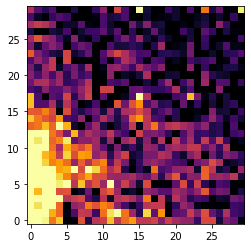

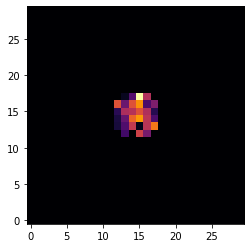

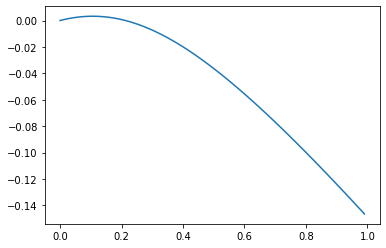

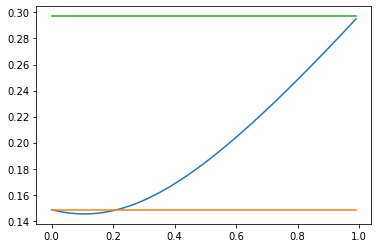

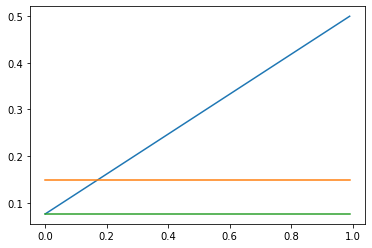

In [20]:
# récupérer une PSF de la simulation et l'injecter dans l'image en ajustant son flux
# jusqu'à ce qu'elle ne soit plus détectée puis mesure photométrique de la PSF simulée

path_sim = '/home/cperrot/Work/projet/JWST/Target/GO/P3662/output_with_photom/planet_attenuation/'

#NW
filename_1  = 'MIRI_2024_attenuation_NW_HD181327_F1140C.fits'
file_sepx_1 = 'MIRI_2024_attenuation_NW_HD181327_F1140C_SEP-X.fits'
file_sepy_1 = 'MIRI_2024_attenuation_NW_HD181327_F1140C_SEP-Y.fits'

#SW
filename_2  = 'MIRI_2024_attenuation_SW_HD181327_F1140C.fits'
file_sepx_2 = 'MIRI_2024_attenuation_SW_HD181327_F1140C_SEP-X.fits'
file_sepy_2 = 'MIRI_2024_attenuation_SW_HD181327_F1140C_SEP-Y.fits'

#NE
filename_3  = 'MIRI_2024_attenuation_NE_HD181327_F1140C.fits'
file_sepx_3 = 'MIRI_2024_attenuation_NE_HD181327_F1140C_SEP-X.fits'
file_sepy_3 = 'MIRI_2024_attenuation_NE_HD181327_F1140C_SEP-Y.fits'

#SE
filename_4  = 'MIRI_2024_attenuation_SE_HD181327_F1140C.fits'
file_sepx_4 = 'MIRI_2024_attenuation_SE_HD181327_F1140C_SEP-X.fits'
file_sepy_4 = 'MIRI_2024_attenuation_SE_HD181327_F1140C_SEP-Y.fits'


image = RDI_1140_2_c.copy() #copie de l'image RDI roll 2
V3i_1   = header_tar_1[1]['V3I_YANG']  # 4.83544897 #4QPM rotation
ydim = np.shape(image)[-2]
xdim = np.shape(image)[-1]


#lam*3600*180/6.5/np.pi*1.5/pixscale # taille en pixel de 1.5 lambda/D
mask2 = np.ndarray([200,200],dtype=bool)*False
mask_psf = np.ndarray([6,6],dtype=bool)
mask_psf = [[False, True, True, True, True, False],
           [True, True, True, True, True, True],
           [True, True, True, True, True, True],
           [True, True, True, True, True, True],
           [True, True, True, True, True, True],
           [False, True, True, True, True, False]]



#NW + initialisation
file  = fits.open(path_sim+filename_1)
fileX = fits.open(path_sim+file_sepx_1)
fileY = fits.open(path_sim+file_sepy_1)
psf_coro = file[0].data
npsf= np.shape(psf_coro)[0]
plan_sepX = np.zeros(npsf*4, dtype='float32')
plan_sepY = np.zeros(npsf*4, dtype='float32')
plan_sepX[:npsf] = fileX[0].data
plan_sepY[:npsf] = fileY[0].data
file.close()
fileX.close()
fileY.close()

n=736
cpsfx = round(plan_sepX[n]/pixscale + 0.5) #centre de la PSF
cpsfy = round(plan_sepY[n]/pixscale + 0.5) #centre de la PSF
psf_i = psf_coro[n,:,:].copy()
#psf_i = ndimage.rotate(psf_i, (V3i_1), reshape=False)  
psf_i /= np.max(psf_i)


#plt.imshow(psf_i,origin='lower',cmap='inferno',interpolation='none',vmin=0.0,vmax=0.1)
#plt.show()

mask_cpsf = mask2.copy()
mask_cpsf[ydim//2+cpsfy-3:ydim//2+cpsfy+3,xdim//2+cpsfx-3:xdim//2+cpsfx+3] = mask_psf
mask_sel = (mask_cpsf == True)
sum_psf = []# np.zeros(n_coef)
max_psf = []# np.zeros(n_coef)
std_im_fp = [] # np.zeros(n_coef)
sum_im_fp = [] # np.zeros(n_coef)
std_im  = np.std(image[mask_sel])
sum_im  = np.sum(image[mask_sel])

coefs = np.arange(0.0001,1.0,0.01)
for c_fp in coefs:
    im_fp = image+psf_i*c_fp
    sum_psf.append(np.sum(c_fp*psf_i[mask_sel]))
    max_psf.append(np.max(c_fp*psf_i[mask_sel]))
    std_im_fp.append(np.std(im_fp[mask_sel]))
    sum_im_fp.append(np.sum(im_fp[mask_sel]))

im_fp = image+psf_i*coefs[(std_im-std_im_fp < 0 )][0]
im_fp = image+psf_i*coefs[(std_im_fp > 1*std_im )][0]
#print(sum_psf,std_im,std_im_fp,std_im-std_im_fp)

plt.imshow(im_fp[ydim//2+cpsfy-15:ydim//2+cpsfy+15,xdim//2+cpsfx-15:xdim//2+cpsfx+15],origin='lower',cmap='inferno',interpolation='none',vmin=0.0,vmax=0.4)
plt.show()
plt.imshow((im_fp*mask_cpsf)[ydim//2+cpsfy-15:ydim//2+cpsfy+15,xdim//2+cpsfx-15:xdim//2+cpsfx+15],origin='lower',cmap='inferno',interpolation='none',vmin=0.0,vmax=0.4)
plt.show()

plt.plot(coefs,std_im-std_im_fp)
plt.show()

plt.plot(coefs,std_im_fp)
plt.plot(coefs,np.zeros(np.shape(coefs)[0])+std_im)
plt.plot(coefs,np.zeros(np.shape(coefs)[0])+std_im*2)
plt.show()

plt.plot(coefs,sum_im_fp/np.sum(mask_psf))
plt.plot(coefs,np.zeros(np.shape(coefs)[0])+std_im)
plt.plot(coefs,np.zeros(np.shape(coefs)[0])+sum_im/np.sum(mask_psf))
plt.show()

### Background analyses

Loading of 2 cubes.
Number of dimension : 2
Initial images size (px) : 288 / 224
New images size (px)     : 288 / 224
Loading of 2 cubes.
Number of dimension : 2
Initial images size (px) : 288 / 224
New images size (px)     : 288 / 224


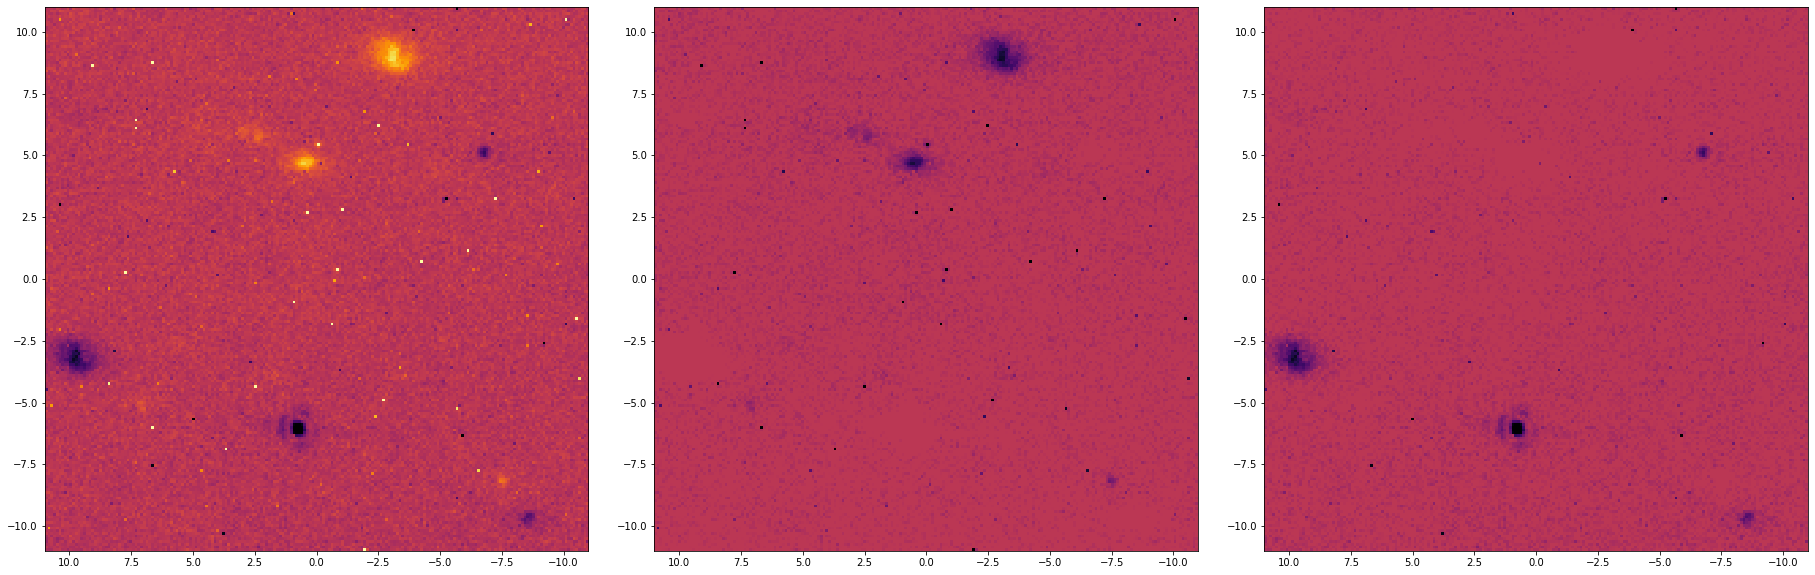

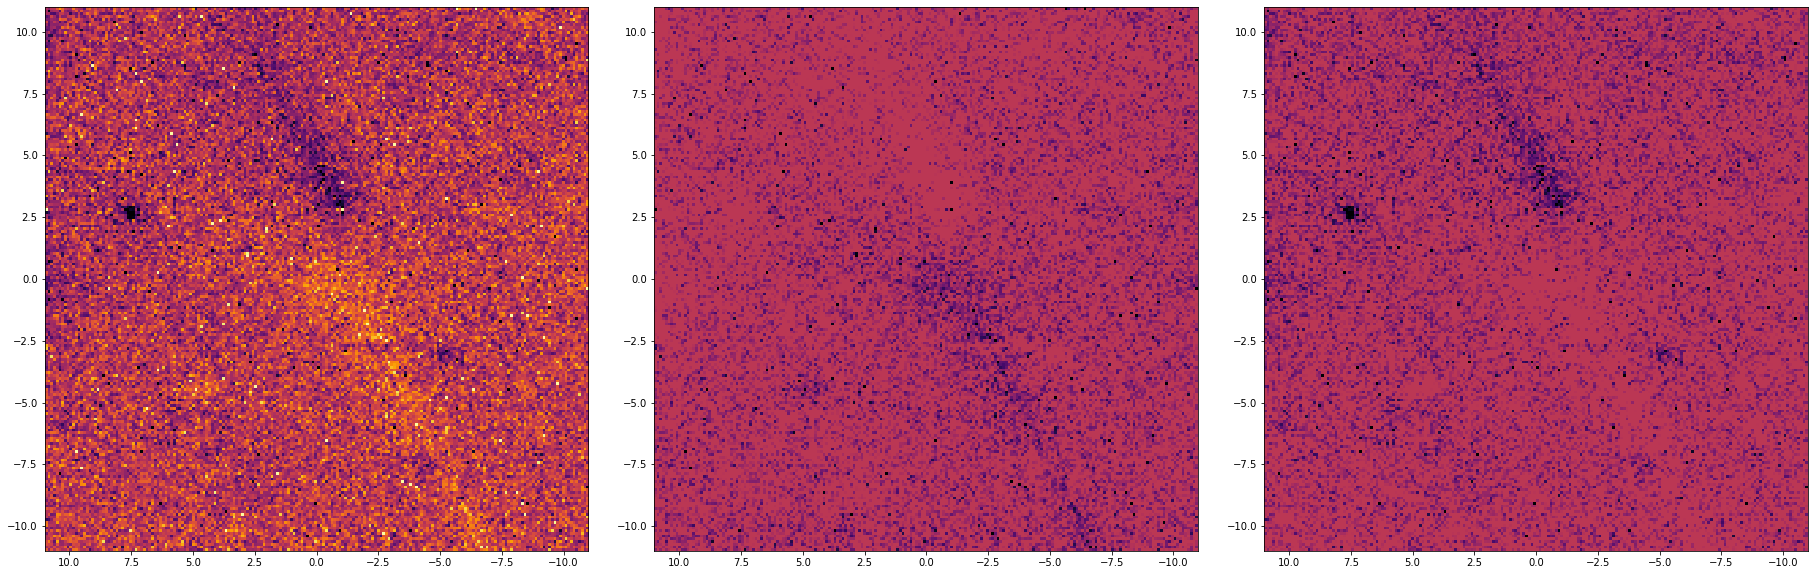

In [21]:
#### Analyse des background pour voir si y a des sources dedans qui font iech

aff  = 'rate'

path_bkg_1  = '/home/cperrot/Work/raw/JWST/Target/MAST/P3662/obs008/'
path_bkg_2  = '/home/cperrot/Work/raw/JWST/Target/MAST/P3662/obs010/'

cube_bkg_1 ,header_bkg_1   = imp.load_cube(path_bkg_1,aff)
cube_bkg_2 ,header_bkg_2   = imp.load_cube(path_bkg_2,aff)


diff_bkg_1 = cube_bkg_1[0]-cube_bkg_1[1]
diff_bkg_2 = cube_bkg_2[0]-cube_bkg_2[1]
min_bkg_1  = np.ndarray([200,200])
min_bkg_2  = np.ndarray([200,200])


#resize
newd = 200
xd = np.shape(diff_bkg_1)[1]
yd = np.shape(diff_bkg_1)[0]
x0 = 119
y0 = 112
scale=[(newd/2.)*pixscale,-1*(newd/2.)*pixscale,-1*(newd/2.)*pixscale,(newd/2.)*pixscale]

diff_bkg_1 = diff_bkg_1[y0-newd//2:y0+newd//2,x0-newd//2:x0+newd//2]
diff_bkg_2 = diff_bkg_2[y0-newd//2:y0+newd//2,x0-newd//2:x0+newd//2]
tmp1       = cube_bkg_1[0][y0-newd//2:y0+newd//2,x0-newd//2:x0+newd//2]
tmp2       = cube_bkg_1[1][y0-newd//2:y0+newd//2,x0-newd//2:x0+newd//2]
tmp3       = cube_bkg_2[0][y0-newd//2:y0+newd//2,x0-newd//2:x0+newd//2]
tmp4       = cube_bkg_2[1][y0-newd//2:y0+newd//2,x0-newd//2:x0+newd//2]





diff_bkg_1 = imp.clean_image_nan(diff_bkg_1)
diff_bkg_2 = imp.clean_image_nan(diff_bkg_2)
#min_bkg_1 = imp.clean_image_nan(min_bkg_1)
#min_bkg_2 = imp.clean_image_nan(min_bkg_2)
tmp1 = imp.clean_image_nan(tmp1)
tmp2 = imp.clean_image_nan(tmp2)
tmp3 = imp.clean_image_nan(tmp3)
tmp4 = imp.clean_image_nan(tmp4)


for i in range(newd):
    for j in range(newd):
        min_bkg_1[i,j] = np.min([tmp1[i,j],tmp2[i,j]])
        min_bkg_2[i,j] = np.min([tmp3[i,j],tmp4[i,j]])
       # print([tmp1[i,j],tmp2[i,j]],np.min([tmp1[i,j],tmp2[i,j]]))

fig1,[sub1,sub2,sub3] = plt.subplots(nrows=1,ncols=3,figsize=(25,10))
plt.subplots_adjust(wspace=0.12, hspace=0.05, left=0.01, right=0.99)
sub1.imshow(diff_bkg_1,origin='lower',cmap='inferno',interpolation='none',vmin=-0.5,vmax=0.5,extent=scale)
sub2.imshow(min_bkg_1-tmp1,origin='lower',cmap='inferno',interpolation='none',vmin=-0.5,vmax=0.5,extent=scale)
sub3.imshow(min_bkg_1-tmp2,origin='lower',cmap='inferno',interpolation='none',vmin=-0.5,vmax=0.5,extent=scale)
#fig1.savefig(path_save+'HD181327_stddev_mask.pdf',format='pdf',bbox_inches='tight')
#plt.close(fig1)
plt.show()

fig1,[sub1,sub2,sub3] = plt.subplots(nrows=1,ncols=3,figsize=(25,10))
plt.subplots_adjust(wspace=0.12, hspace=0.05, left=0.01, right=0.99)
sub1.imshow(diff_bkg_2,origin='lower',cmap='inferno',interpolation='none',vmin=-0.5,vmax=0.5,extent=scale)
sub2.imshow(min_bkg_2-tmp3,origin='lower',cmap='inferno',interpolation='none',vmin=-0.5,vmax=0.5,extent=scale)
sub3.imshow(min_bkg_2-tmp4,origin='lower',cmap='inferno',interpolation='none',vmin=-0.5,vmax=0.5,extent=scale)
#fig1.savefig(path_save+'HD181327_stddev_mask.pdf',format='pdf',bbox_inches='tight')
#plt.close(fig1)
plt.show()


Loading of 2 cubes.
Number of dimension : 2
Initial images size (px) : 288 / 224
New images size (px)     : 288 / 224
Loading of 2 cubes.
Number of dimension : 2
Initial images size (px) : 288 / 224
New images size (px)     : 288 / 224


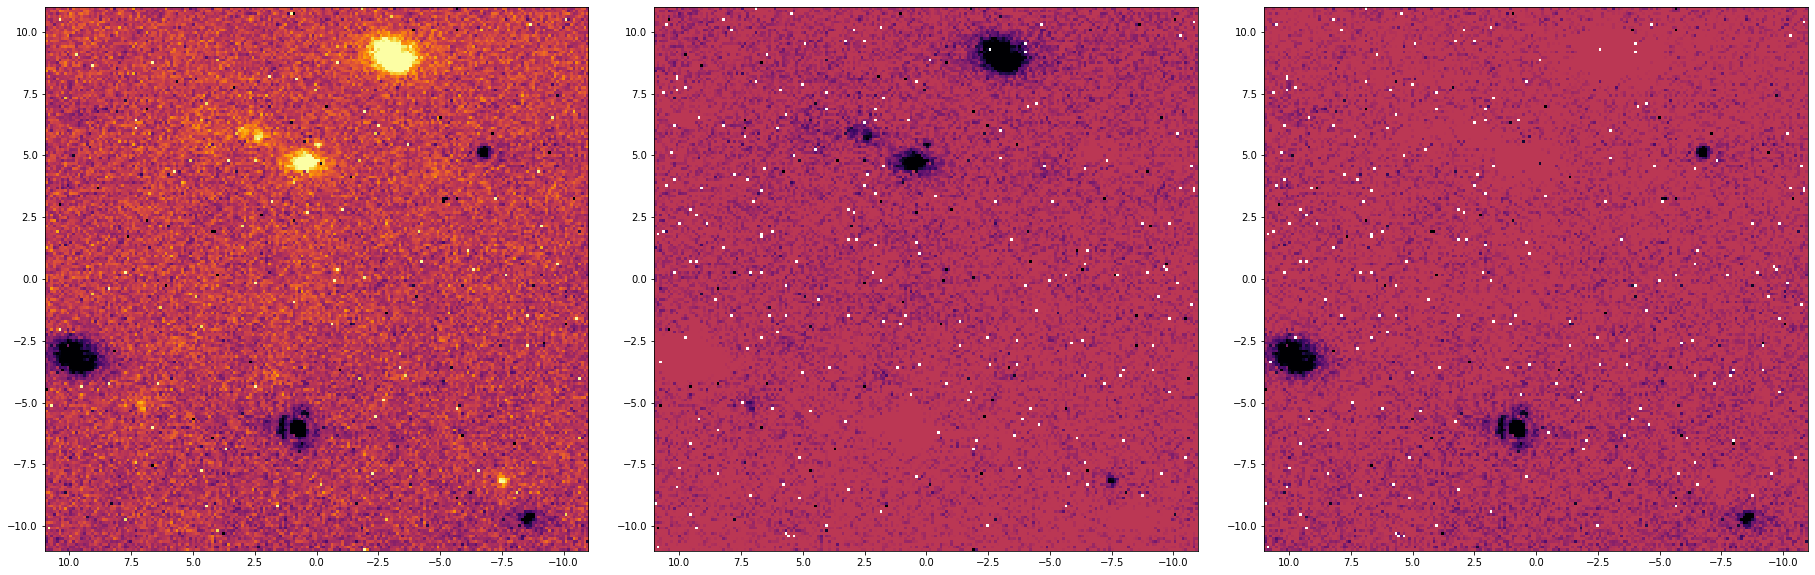

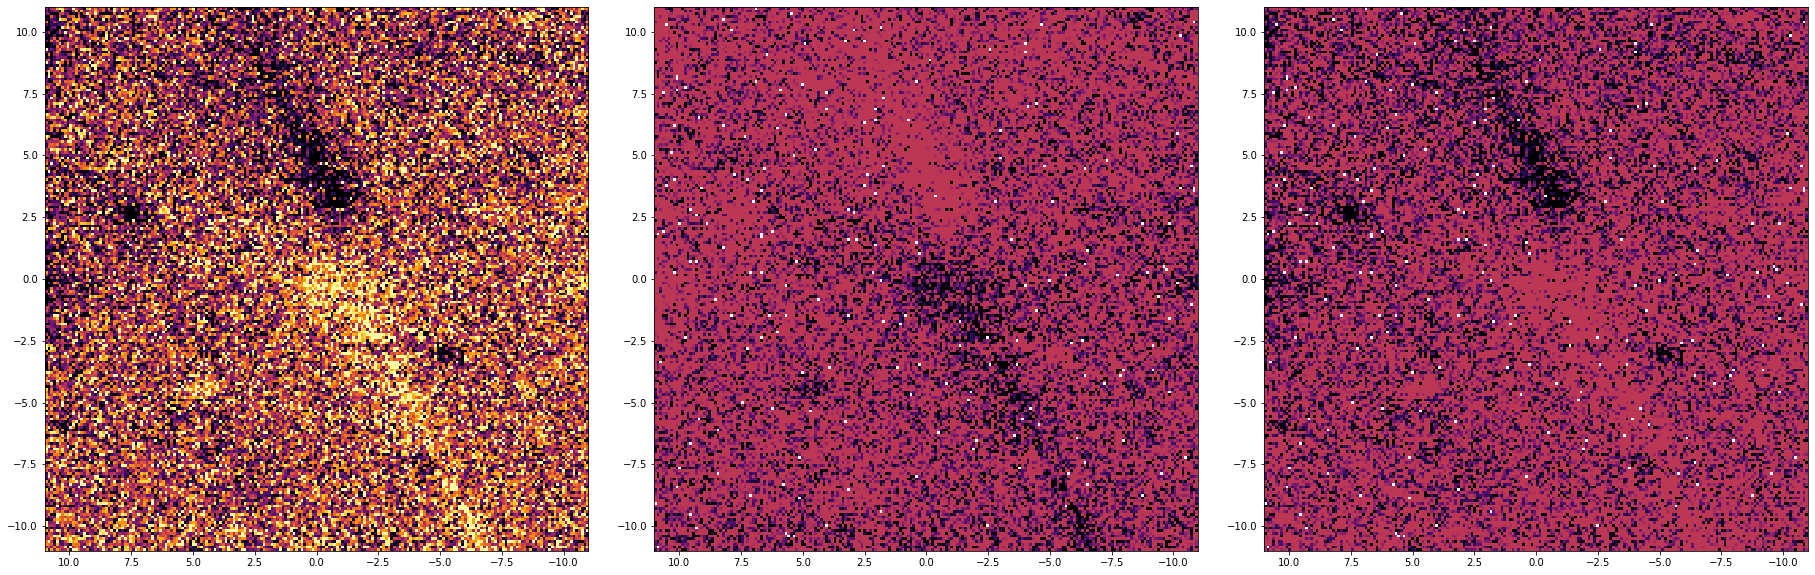

In [22]:
#### Analyse des background calibrés séparemment en stage 2

aff  = 'cal'

path_bkg_1  = '/home/cperrot/Work/raw/JWST/Target/MAST/P3662/output_with_photom/obs008/'
path_bkg_2  = '/home/cperrot/Work/raw/JWST/Target/MAST/P3662/output_with_photom/obs010/'

cube_bkg_1 ,header_bkg_1   = imp.load_cube(path_bkg_1,aff)
cube_bkg_2 ,header_bkg_2   = imp.load_cube(path_bkg_2,aff)


diff_bkg_1 = cube_bkg_1[0]-cube_bkg_1[1]
diff_bkg_2 = cube_bkg_2[0]-cube_bkg_2[1]
min_bkg_1  = np.ndarray([200,200])
min_bkg_2  = np.ndarray([200,200])


#resize
newd = 200
xd = np.shape(diff_bkg_1)[1]
yd = np.shape(diff_bkg_1)[0]
x0 = 119
y0 = 112
scale=[(newd/2.)*pixscale,-1*(newd/2.)*pixscale,-1*(newd/2.)*pixscale,(newd/2.)*pixscale]

diff_bkg_1 = diff_bkg_1[y0-newd//2:y0+newd//2,x0-newd//2:x0+newd//2]
diff_bkg_2 = diff_bkg_2[y0-newd//2:y0+newd//2,x0-newd//2:x0+newd//2]
tmp1      = cube_bkg_1[0][y0-newd//2:y0+newd//2,x0-newd//2:x0+newd//2]
tmp2      = cube_bkg_1[1][y0-newd//2:y0+newd//2,x0-newd//2:x0+newd//2]
tmp3      = cube_bkg_2[0][y0-newd//2:y0+newd//2,x0-newd//2:x0+newd//2]
tmp4      = cube_bkg_2[1][y0-newd//2:y0+newd//2,x0-newd//2:x0+newd//2]





diff_bkg_1 = imp.clean_image_nan(diff_bkg_1)
diff_bkg_2 = imp.clean_image_nan(diff_bkg_2)
#min_bkg_1  = imp.clean_image_nan(min_bkg_1)
#min_bkg_2  = imp.clean_image_nan(min_bkg_2)
#tmp1 = imp.clean_image_nan(tmp1)
#tmp2 = imp.clean_image_nan(tmp2)
#tmp3 = imp.clean_image_nan(tmp3)
#tmp4 = imp.clean_image_nan(tmp4)


for i in range(newd):
    for j in range(newd):
        min_bkg_1[i,j] = np.min([tmp1[i,j],tmp2[i,j]])
        min_bkg_2[i,j] = np.min([tmp3[i,j],tmp4[i,j]])
       # print([tmp1[i,j],tmp2[i,j]],np.min([tmp1[i,j],tmp2[i,j]]))

fig1,[sub1,sub2,sub3] = plt.subplots(nrows=1,ncols=3,figsize=(25,10))
plt.subplots_adjust(wspace=0.12, hspace=0.05, left=0.01, right=0.99)
sub1.imshow(diff_bkg_1,origin='lower',cmap='inferno',interpolation='none',vmin=-0.5,vmax=0.5,extent=scale)
sub2.imshow(min_bkg_1-tmp1,origin='lower',cmap='inferno',interpolation='none',vmin=-0.5,vmax=0.5,extent=scale)
sub3.imshow(min_bkg_1-tmp2,origin='lower',cmap='inferno',interpolation='none',vmin=-0.5,vmax=0.5,extent=scale)
#fig1.savefig(path_save+'HD181327_stddev_mask.pdf',format='pdf',bbox_inches='tight')
#plt.close(fig1)
plt.show()

fig1,[sub1,sub2,sub3] = plt.subplots(nrows=1,ncols=3,figsize=(25,10))
plt.subplots_adjust(wspace=0.12, hspace=0.05, left=0.01, right=0.99)
sub1.imshow(diff_bkg_2,origin='lower',cmap='inferno',interpolation='none',vmin=-0.5,vmax=0.5,extent=scale)
sub2.imshow(min_bkg_2-tmp3,origin='lower',cmap='inferno',interpolation='none',vmin=-0.5,vmax=0.5,extent=scale)
sub3.imshow(min_bkg_2-tmp4,origin='lower',cmap='inferno',interpolation='none',vmin=-0.5,vmax=0.5,extent=scale)
#fig1.savefig(path_save+'HD181327_stddev_mask.pdf',format='pdf',bbox_inches='tight')
#plt.close(fig1)
plt.show()

### test sur le roll 1

5.392149925231934
5.392149925231934
1.785068349968313
10.747354975136872
0.03694487532699409


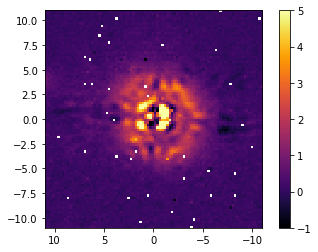

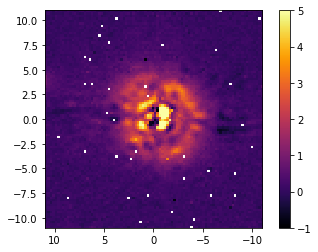

In [24]:
print(cube_tar_1[91][91])

med= np.nanmean(cube_tar_1[91-1:91+2,91-1:91+2])
std= np.nanstd(cube_tar_1)#[91-1:91+2,91-1:91+2])
print(med)
print(std)
print(med+clipval*std)
print(med-clipval*std)


#scipy.ndimage.shift(input, shift, output=None, order=3, mode='constant', cval=0.0, prefilter=True)


f_scale_1=0.101631779837534*0.9999

RDI_1140_1 = imp.RDI_classic(ndimage.shift(cube_tar_1,[-0.0,-0.0]), cube_ref, f_scale=f_scale_1)

z=45
plt.imshow(RDI_1140_1[newd//2-z:newd//2+z,newd//2-z:newd//2+z],origin='lower',cmap='inferno',interpolation='none',vmin=-1,vmax=5,extent=scale)
plt.colorbar()
plt.show()

RDI_1140_1 = imp.RDI_classic(ndimage.shift(cube_tar_1,[0.0,0.1]), cube_ref, f_scale=f_scale_1)

plt.imshow(RDI_1140_1[newd//2-z:newd//2+z,newd//2-z:newd//2+z],origin='lower',cmap='inferno',interpolation='none',vmin=-1,vmax=5,extent=scale)
plt.colorbar()
plt.show()